# **To install necessary dependencies:**

In [ ]:
# @title [Step 1] Installing Dependencies

import subprocess
import sys
import importlib
import os
import signal

def check_and_install(package_name, import_name=None):
	if import_name is None:
		import_name = package_name
	try:
		importlib.import_module(import_name)
		print(f"✅ {package_name} is already installed.")
	except ImportError:
		print(f"⬇️ Installing {package_name}...")
		subprocess.check_call([sys.executable, "-m", "pip", "install", package_name, "-q"])
		print(f"✅ {package_name} installed successfully.")

print("--- INITIALIZING CONTEXT STREAM ENVIRONMENT ---\n")

# 1. Hardware Acceleration (NVIDIA RAPIDS cuML) - DO THIS FIRST!
try:
	importlib.import_module("cuml")
	print("✅ cuml (NVIDIA RAPIDS) is already installed.")
except ImportError:
	print("⬇️ Installing NVIDIA RAPIDS (cuML)...")
	print("⏳ Please wait 2-3 minutes. This is a massive library pulled directly from NVIDIA's servers.")
	subprocess.check_call([sys.executable, "-m", "pip", "install", "cuml-cu12", "--extra-index-url", "https://pypi.nvidia.com", "-q"])
	print("✅ NVIDIA RAPIDS installed successfully.")

# 2. Computer Vision & 3D Processing
check_and_install("ultralytics")
check_and_install("open3d")
check_and_install("einops")

# 3. Dependency Safety Net
print("⬇️ Securing Pandas C-API synchronization...")
subprocess.check_call([sys.executable, "-m", "pip", "install", "pandas", "--upgrade", "-q"])

# 4. The ZoeDepth Strict Dependency Lock (DO THIS LAST)
try:
	import timm
	if timm.__version__ == "0.6.7":
		print("✅ timm==0.6.7 is perfectly synced.")
	else:
		raise ImportError
except ImportError:
	print("⚠️ Incompatible timm version detected after installing heavy packages.")
	print("🧹 Forcing strict downgrade to ZoeDepth's required version (0.6.7)...")
	subprocess.check_call([sys.executable, "-m", "pip", "install", "timm==0.6.7", "-q"])
	print("🔄 AUTO-RESTARTING COLAB RUNTIME TO APPLY CHANGES...")
	print("▶️ PLEASE RUN STEP 1 AGAIN ONCE IT RESTARTS.")
	os.kill(os.getpid(), signal.SIGKILL)

print("\n--- SYSTEM READY ---")

--- INITIALIZING CONTEXT STREAM ENVIRONMENT ---

✅ cuml (NVIDIA RAPIDS) is already installed.
⬇️ Installing ultralytics...
✅ ultralytics installed successfully.
⬇️ Installing open3d...
✅ open3d installed successfully.
✅ einops is already installed.
⬇️ Securing Pandas C-API synchronization...
⚠️ Incompatible timm version detected after installing heavy packages.
🧹 Forcing strict downgrade to ZoeDepth's required version (0.6.7)...


**The Initial Knowledge Base (Semantic Memory)**





In [ ]:
# @title [Step 2] Master Knowledge Base (Stateless Version)
# ==============================================================================

# 1. MATERIAL DENSITY LIBRARY (Strictly in g/mm^3)
MATERIAL_DENSITY = {
	# --- BOTTLES ---
	"PLASTIC_BOTTLE": 0.00138,  # Standard PET (Polyethylene Terephthalate)
	"GLASS_BOTTLE": 0.00250,    # Standard Soda-Lime Glass
	"METAL_BOTTLE": 0.00270,    # Aluminum (Standard for hydroflasks/sports bottles)
	"CERAMIC_BOTTLE": 0.00240,  # Fallback for stoneware containers
	"PAPER_BOTTLE": 0.00080,    # TetraPak style paperboard

	# --- CUPS ---
	"PLASTIC_CUP": 0.00090,     # Standard PP (Polypropylene)
	"GLASS_CUP": 0.00240,       # Borosilicate or standard drinking glass
	"CERAMIC_CUP": 0.00240,     # Standard Porcelain/Stoneware Mug
	"METAL_CUP": 0.00785,       # Stainless Steel Tumbler/Mug
	"PAPER_CUP": 0.00080,       # Pressed Kraft Paper

	# --- BOWLS ---
	"PLASTIC_BOWL": 0.00151,    # Melamine or heavy-duty polymer
	"CERAMIC_BOWL": 0.00240,    # Stoneware/Porcelain
	"GLASS_BOWL": 0.00250,      # Pyrex/Soda-lime mixing bowl
	"METAL_BOWL": 0.00785,      # Stainless Steel Mixing Bowl
	"PAPER_BOWL": 0.00080,      # Disposable pressed paperboard

	# --- SPORTS BALLS ---
	"PLASTIC_SPORTS_BALL": 0.00102, # Rigid Plastic (ABS / HDPE for Ping Pong / Pickleball)
}

# 2. DYNAMIC FRICTION LIBRARY (Slip Resistance)
FRICTION_LIBRARY = {
	"plastic": 0.50,
	"glass": 0.68,
	"metal": 0.65,
	"ceramic": 0.60,
	"paper": 0.45
}

# 3. SOLIDITY TABLE (Compound Key: MATERIAL_OBJECT)
SOLIDITY_TABLE = {
	# --- BOTTLES ---
	"PLASTIC_BOTTLE": 0.1314, # Thin disposable water bottles
	"GLASS_BOTTLE": 0.1830, # Thicker wine or soda bottles
	"METAL_BOTTLE": 0.1777, # Insulated flasks (Hydroflask, etc.)
	"PAPER_BOTTLE": 0.05, # Milk cartons
	"CERAMIC_BOTTLE": 0.10, # Heavy decorative bottles or jugs

	# --- CUPS ---
	"PLASTIC_CUP": 0.1157,  # Solo cups, fast food cups
	"GLASS_CUP": 0.1546,    # Drinking glasses
	"METAL_CUP": 0.0502,    # Camping mugs
	"PAPER_CUP": 0.0268,    # Coffee shop disposable cups
	"CERAMIC_CUP": 0.1397,  # Thick coffee mugs

	# --- BOWLS ---
	"PLASTIC_BOWL": 0.1772, # Tupperware, disposable bowls
	"GLASS_BOWL": 0.1356,   # Pyrex, mixing bowls
	"METAL_BOWL": 0.0501,   # Thin stainless steel mixing bowls
	"PAPER_BOWL": 0.0363,   # Takeout containers
	"CERAMIC_BOWL": 0.1443, # Heavy dining bowls

	# --- SPORTS BALLS ---
	"PLASTIC_SPORTS_BALL": 0.1147, # Hollow plastic balls
}

print("✅ Static Knowledge Base Loaded.")

✅ Static Knowledge Base Loaded.


In [ ]:
# @title [Step 3] Initialize AI (Vision, Depth & Logic Core)
import torch
import cv2
import numpy as np
import os
import sys
import subprocess
from ultralytics import YOLO

print("--- LOADING COMPUTATIONAL MODELS ---")

# --- DOUBLE CHECK SYNC ---
import timm
if timm.__version__ != "0.6.7":
	print("❌ ERROR: timm version mismatch. Please go back and run Step 1 to auto-restart the environment.")
	sys.exit(1)

# 1. Load Semantic Model (YOLO11 Segmentation)
print("1. Loading YOLO11-Extra Large (Segmentation Recognition)...")
try:
	yolo_model = YOLO('yolo11x-seg.pt') # UPGRADED: For precise masking
except Exception as e:
	print(f"  Error loading model: {e}")
	yolo_model = YOLO('yolo11x-seg.pt')

# 2. Load Depth Model (ZoeDepth - Metric)
print("2. Loading ZoeDepth (Metric Depth Engine)...")
checkpoint_path = os.path.expanduser("~/.cache/torch/hub/checkpoints/ZoeD_M12_N.pt")

try:
	zoe = torch.hub.load("isl-org/ZoeDepth", "ZoeD_N", pretrained=True, trust_repo=True)
except Exception as e:
	print(f"⚠️ Corrupted download or state_dict detected: {e}")
	print("🧹 Clearing broken cache and forcing a fresh download...")
	if os.path.exists(checkpoint_path):
		os.remove(checkpoint_path)
	zoe = torch.hub.load("isl-org/ZoeDepth", "ZoeD_N", pretrained=True, force_reload=True, trust_repo=True)

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
zoe.to(device)
zoe.eval()

# --- LOGIC CORE ---
def determine_grasp_strategy(dims, orientation_angle, compliance):
	length, width, depth = dims
	wrist_command = round(orientation_angle, 1)
	aspect_ratio = width / depth if depth > 0 else 1
	strategy = "Power Grasp"

	if width < 50 or depth < 20:
		strategy = "Pinch Grasp"
	elif 0.8 < aspect_ratio < 1.2:
		if compliance == "Soft":
			strategy = "Spherical Grasp"
		else:
			strategy = "Power Grasp"
	else:
		strategy = "Cylindrical Grasp"

	if compliance == "Soft":
		safety_note = "Precision Mode"
	elif compliance == "Semi-Compliant":
		safety_note = "Standard Mode"
	else:
		safety_note = "High-Torque Mode"

	return strategy, wrist_command, safety_note

def calculate_forces(mass_g, friction, distance_mm):
	mass_kg = mass_g / 1000.0 # Physics calculations strictly require kg
	g = 9.81
	slip = (mass_kg * g) / friction if friction > 0.05 else 10.0
	torque = (mass_kg * g) * (distance_mm / 1000.0)
	return round(slip, 2), round(torque, 3)

print(f"\n✅ SYSTEM READY: YOLO11-Seg & ZoeDepth loaded on {device}.")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
--- LOADING COMPUTATIONAL MODELS ---
1. Loading YOLO11-Extra Large (Segmentation Recognition)...
2. Loading ZoeDepth (Metric Depth Engine)...
Downloading: "https://github.com/isl-org/ZoeDepth/zipball/main" to /root/.cache/torch/hub/main.zip
img_size [384, 512]


/usr/local/lib/python3.12/dist-packages/torch/hub.py:247: UserWarning: You are about to download and run code from an untrusted repository. In a future release, this won't be allowed. To add the repository to your trusted list, change the command to load(..., trust_repo=False) and a command prompt will appear asking for an explicit confirmation of trust, or load(..., trust_repo=True), which will assume that the prompt is to be answered with 'yes'. You can also use load(..., trust_repo='check') which will only prompt for confirmation if the repo is not already trusted. This will eventually be the default behaviour
  _check_repo_is_trusted(


Downloading: "https://github.com/intel-isl/MiDaS/zipball/master" to /root/.cache/torch/hub/master.zip


/usr/local/lib/python3.12/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Params passed to Resize transform:
	width:  512
	height:  384
	resize_target:  True
	keep_aspect_ratio:  True
	ensure_multiple_of:  32
	resize_method:  minimal
Using pretrained resource url::https://github.com/isl-org/ZoeDepth/releases/download/v1.0/ZoeD_M12_N.pt
Downloading: "https://github.com/isl-org/ZoeDepth/releases/download/v1.0/ZoeD_M12_N.pt" to /root/.cache/torch/hub/checkpoints/ZoeD_M12_N.pt


100%|██████████| 1.34G/1.34G [00:37<00:00, 38.4MB/s]


Loaded successfully

✅ SYSTEM READY: YOLO11-Seg & ZoeDepth loaded on cuda.


# **Model Training**

In [ ]:
# @title Dataset Prep: Local Transfer
import os
import shutil

PROJECT_ROOT = '/content/drive/MyDrive/AxisPowers/Thesis/MODEL'

# 1. Your manually split folders on Google Drive
DRIVE_TRAIN_DIR = os.path.join(PROJECT_ROOT, "dataset_master/dataset_train")
DRIVE_VAL_DIR = os.path.join(PROJECT_ROOT, "dataset_master/dataset_val")

# 2. Local High-Speed SSD Paths (Where the AI trains from)
LOCAL_TRAIN_DIR = "/content/local_dataset_train"
LOCAL_VAL_DIR = "/content/local_dataset_val"

def transfer_datasets():
	print("⚡ Copying your manually split datasets to local SSD for high-speed training...")

	# Verify your manual folders exist
	if not os.path.exists(DRIVE_TRAIN_DIR):
		print(f"❌ Error: Could not find training folder at {DRIVE_TRAIN_DIR}")
		return
	if not os.path.exists(DRIVE_VAL_DIR):
		print(f"❌ Error: Could not find validation folder at {DRIVE_VAL_DIR}")
		return

	# Clear existing local data to prevent overlap if run multiple times
	if os.path.exists(LOCAL_TRAIN_DIR):
		shutil.rmtree(LOCAL_TRAIN_DIR)
	if os.path.exists(LOCAL_VAL_DIR):
		shutil.rmtree(LOCAL_VAL_DIR)

	print("⏳ Copying Training Data... (This may take a minute)")
	shutil.copytree(DRIVE_TRAIN_DIR, LOCAL_TRAIN_DIR)

	print("⏳ Copying Validation Data... (This may take a minute)")
	shutil.copytree(DRIVE_VAL_DIR, LOCAL_VAL_DIR)

	# Count the files to give you a confirmation summary
	total_train = sum([len(files) for r, d, files in os.walk(LOCAL_TRAIN_DIR)])
	total_val = sum([len(files) for r, d, files in os.walk(LOCAL_VAL_DIR)])

	print("------------------------------------------")
	print(f"🎯 TRANSFER COMPLETE: \t{total_train} Train \t| {total_val} Val")

print("--- INITIATING DATASET TRANSFER ---")
transfer_datasets()
print("✅ Ready for Step 4.")

--- INITIATING DATASET TRANSFER ---
⚡ Copying your manually split datasets to local SSD for high-speed training...
⏳ Copying Training Data... (This may take a minute)
⏳ Copying Validation Data... (This may take a minute)
------------------------------------------
🎯 TRANSFER COMPLETE: 	800 Train 	| 200 Val
✅ Ready for Step 4.


In [ ]:
# @title [Step 4] Training MobileNetV2 (Material Analyzer)
import torch
import torch.nn as nn
from PIL import Image
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
import torchvision.transforms as T
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
import os
from tqdm import tqdm
from collections import Counter

# --- OVERRIDE PIL SAFETY LIMIT ---
Image.MAX_IMAGE_PIXELS = None

PROJECT_ROOT = '/content/drive/MyDrive/AxisPowers/Thesis/MODEL'
model_save_path = os.path.join(PROJECT_ROOT, "models", "material_model.pth")

# Data directories created in Step 3.5
TRAIN_DIR = "/content/local_dataset_train"
VAL_DIR = "/content/local_dataset_val"

# --- SAFETY OVERWRITE PROTECTION ---
if os.path.exists(model_save_path):
	print(f"🛑 Existing model detected at: {model_save_path}")
	print("⏭️ Training aborted to prevent overwriting your prototype. If you wish to retrain, please delete or rename the existing .pth file first.")
else:
	if not os.path.exists(TRAIN_DIR) or not os.path.exists(VAL_DIR):
		print("❌ Error: Local datasets not found. Please run Dataset Prep: Local Transfer first!")
	else:
		# --- TRAINING CONFIGURATION ---
		batch_size = 32
		epochs = 7

		train_transforms = T.Compose([
			T.RandomResizedCrop(224, scale=(0.6, 1.0)),
			T.RandomHorizontalFlip(),
			T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
			T.ToTensor(),
			T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
			T.RandomErasing(p=0.2, scale=(0.02, 0.1))
		])

		# Validation requires strict, unaltered evaluation data
		val_transforms = T.Compose([
			T.Resize(256),
			T.CenterCrop(224),
			T.ToTensor(),
			T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
		])

		print("Loading Datasets...")
		train_dataset = ImageFolder(root=TRAIN_DIR, transform=train_transforms)
		val_dataset = ImageFolder(root=VAL_DIR, transform=val_transforms)

		# Count the training dataset targets for the final log printout
		class_counts = Counter(train_dataset.targets)

		train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
		val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

		MATERIAL_LABELS = train_dataset.classes
		print(f"Detected Materials: {MATERIAL_LABELS}")

		device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
		model = mobilenet_v2(weights=MobileNet_V2_Weights.DEFAULT)

		# Unfreezing the last 6 blocks
		for param in model.features[:-6].parameters():
			param.requires_grad = False

		# Upgraded Classifier Head (The Feature Sandbox)
		model.classifier = nn.Sequential(
			nn.Dropout(p=0.5),
			nn.Linear(model.last_channel, 512),
			nn.ReLU(),
			nn.Dropout(p=0.3),
			nn.Linear(512, len(MATERIAL_LABELS))
		)
		model.to(device)

		criterion = nn.CrossEntropyLoss()
		optimizer = optim.Adam(model.parameters(), lr=0.0005)
		scheduler = CosineAnnealingLR(optimizer, T_max=epochs)

		print("\n--- Starting Fine-Tuning with 80/20 Validation ---")
		for epoch in range(epochs):
			# 1. TRAINING PHASE
			model.train()
			running_loss = 0.0
			train_correct, train_total = 0, 0

			progress_bar = tqdm(train_loader, desc=f"Epoch [{epoch+1}/{epochs}]", leave=False)
			for images, labels in progress_bar:
				images, labels = images.to(device), labels.to(device)
				optimizer.zero_grad()
				outputs = model(images)
				loss = criterion(outputs, labels)
				loss.backward()
				optimizer.step()

				running_loss += loss.item()
				_, predicted = torch.max(outputs.data, 1)
				train_total += labels.size(0)
				train_correct += (predicted == labels).sum().item()
				progress_bar.set_postfix(loss=f"{loss.item():.4f}")

			# 2. VALIDATION PHASE (Hold-out Evaluation)
			model.eval()
			val_correct, val_total = 0, 0
			with torch.no_grad():
				for val_images, val_labels in val_loader:
					val_images, val_labels = val_images.to(device), val_labels.to(device)
					val_outputs = model(val_images)
					_, val_predicted = torch.max(val_outputs.data, 1)
					val_total += val_labels.size(0)
					val_correct += (val_predicted == val_labels).sum().item()

			scheduler.step()
			current_lr = optimizer.param_groups[0]['lr']

			train_acc = 100 * train_correct / train_total
			val_acc = 100 * val_correct / val_total

			print(f"Epoch [{epoch+1}/{epochs}] | Loss: {running_loss/len(train_loader):.4f} | Train Acc: {train_acc:.1f}% | 🎯 Val Acc: {val_acc:.1f}% (LR: {current_lr:.6f})")

		# Save strictly after successful validation logic
		torch.save(model.state_dict(), model_save_path)
		print(f"\n🎉 Model trained and saved safely to your Drive: {model_save_path}")

		# --- PRINT FINAL DATASET METRICS ---
		print("\n==========================================")
		print("        TRAINING DATASET SUMMARY")
		print("==========================================")
		total_trained = 0
		for class_idx, count in class_counts.items():
			mat_name = MATERIAL_LABELS[class_idx]
			print(f" 🔹 {mat_name.title()}:\t{count} images")
			total_trained += count
		print("------------------------------------------")
		print(f" 🎯 GRAND TOTAL:\t{total_trained} images trained")
		print("==========================================\n")

Loading Datasets...
Detected Materials: ['ceramic', 'glass', 'metal', 'paper', 'plastic']

--- Starting Fine-Tuning with 80/20 Validation ---


Epoch [1/7] | Loss: 1.1568 | Train Acc: 60.1% | 🎯 Val Acc: 70.0% (LR: 0.000475)


Epoch [2/7] | Loss: 0.2762 | Train Acc: 91.1% | 🎯 Val Acc: 77.5% (LR: 0.000406)


Epoch [3/7] | Loss: 0.0783 | Train Acc: 98.2% | 🎯 Val Acc: 73.0% (LR: 0.000306)


Epoch [4/7] | Loss: 0.0548 | Train Acc: 98.1% | 🎯 Val Acc: 75.0% (LR: 0.000194)


Epoch [5/7] | Loss: 0.0366 | Train Acc: 99.1% | 🎯 Val Acc: 78.0% (LR: 0.000094)


Epoch [6/7] | Loss: 0.0218 | Train Acc: 99.5% | 🎯 Val Acc: 76.5% (LR: 0.000025)


Epoch [7/7] | Loss: 0.0159 | Train Acc: 99.6% | 🎯 Val Acc: 76.0% (LR: 0.000000)

🎉 Model trained and saved safely to your Drive: /content/drive/MyDrive/AxisPowers/Thesis/MODEL/models/material_model.pth

        TRAINING DATASET SUMMARY
 🔹 Ceramic:	160 images
 🔹 Glass:	160 images
 🔹 Metal:	160 images
 🔹 Paper:	160 images
 🔹 Plastic:	160 images
------------------------------------------
 🎯 GRAND TOTAL:	800 images trained



In [ ]:
# @title [Step 4A] Spatial Calibration: Execution & Logging
import os
import json
import numpy as np
import pandas as pd
import torch

# --- CONFIGURATION ---
PROJECT_ROOT = '/content/drive/MyDrive/AxisPowers/Thesis/MODEL'
EVAL_DIR = '/content/local_dataset_val'
CSV_PATH = os.path.join(PROJECT_ROOT, "automated_sweep_ground_truth.csv")
LOG_PATH = os.path.join(PROJECT_ROOT, "sweep_metrics_log.csv")
CONFIG_PATH = os.path.join(PROJECT_ROOT, "calibration_config.json")
TEST_MULTIPLIERS = [0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5]

print("--- INITIATING 1D HYPERPARAMETER GRID SEARCH ---")

# --- 1. GPU VERIFICATION ---
if not torch.cuda.is_available():
	print("❌ GPU is OFF. Running this sweep on a CPU will take hours!")
	print("💡 Please go to Runtime > Change runtime type > Select T4 GPU.")

# --- 2. EXISTING CALIBRATION CHECK ---
elif os.path.exists(CONFIG_PATH) and os.path.getsize(CONFIG_PATH) > 0:
	with open(CONFIG_PATH, "r") as f:
		config_data = json.load(f)
		existing_mult = config_data.get("optimal_depth_multiplier")

		if existing_mult is not None:
			print(f"⏭️ Sweep Skipped: Optimal calibration already exists ({existing_mult}x).")
			print(f"💡 If you want to force a re-run, delete the file at: {CONFIG_PATH}")
			print("➡️ You may now run Spatial Calibration: U-Curve Visualization B to view the graph.")

# --- 3. DATASET CHECKS & EXECUTION ---
elif not os.path.exists(EVAL_DIR):
	print(f"❌ Local dataset not found at: {EVAL_DIR}")
	print("💡 Did you forget to run the 'Speed Optimization' cell first?")
elif not os.path.exists(CSV_PATH):
	print(f"❌ Ground truth CSV not found at: {CSV_PATH}")
else:
	gt_df = pd.read_csv(CSV_PATH, index_col="Image_Filename")
	sweep_results = []

	print(f"✅ GPU is active: {torch.cuda.get_device_name(0)}")
	print("Sweeping Z-Guillotine Depth Tolerances...")

	for mult in TEST_MULTIPLIERS:
		print(f"Testing Multiplier: {mult}x...")
		current_errors = []

		for material_folder in os.listdir(EVAL_DIR):
			mat_path = os.path.join(EVAL_DIR, material_folder)

			if os.path.isdir(mat_path):
				for filename in sorted(os.listdir(mat_path)):
					if filename in gt_df.index:
						img_path = os.path.join(mat_path, filename)
						true_mass_g = float(gt_df.loc[filename, "True_Mass_g"])
						true_mat = str(gt_df.loc[filename, "Material"]).lower()
						true_obj = str(gt_df.loc[filename, "Object"]).upper()

						raw, _ = run_pipeline(img_path, is_deployment=False, sweep_mult=mult, override_mat=true_mat, override_obj=true_obj)

						if raw:
							pred_mass_g = raw["mass"]
							error = abs(true_mass_g - pred_mass_g)
							current_errors.append(error)

		if current_errors:
			mae = np.mean(current_errors)
			sweep_results.append({"Multiplier": mult, "MAE_g": mae})

	if sweep_results:
		sweep_df = pd.DataFrame(sweep_results)
		sweep_df.to_csv(LOG_PATH, index=False)
		print(f"\n✅ Data Logged successfully to {LOG_PATH}")

		best_idx = sweep_df['MAE_g'].idxmin()
		best_mult = sweep_df.loc[best_idx, 'Multiplier']
		min_mae = sweep_df.loc[best_idx, 'MAE_g']

		print(f"🏆 Optimal Multiplier Found: {best_mult}x (MAE: {min_mae:.2f}g)")

		with open(CONFIG_PATH, "w") as f:
			json.dump({"optimal_depth_multiplier": float(best_mult)}, f)
		print(f"⚙️ Calibration automatically saved to {CONFIG_PATH}")
		print("➡️ You may now run Spatial Calibration: U-Curve Visualization B to view the U-Curve graph.")
	else:
		print("❌ No valid images processed during the sweep.")

--- INITIATING 1D HYPERPARAMETER GRID SEARCH ---
✅ GPU is active: Tesla T4
Sweeping Z-Guillotine Depth Tolerances...
Testing Multiplier: 0.8x...
Testing Multiplier: 0.9x...
Testing Multiplier: 1.0x...
Testing Multiplier: 1.1x...
Testing Multiplier: 1.2x...
Testing Multiplier: 1.3x...
Testing Multiplier: 1.4x...
Testing Multiplier: 1.5x...

✅ Data Logged successfully to /content/drive/MyDrive/AxisPowers/Thesis/MODEL/sweep_metrics_log.csv
🏆 Optimal Multiplier Found: 0.8x (MAE: 142.16g)
⚙️ Calibration automatically saved to /content/drive/MyDrive/AxisPowers/Thesis/MODEL/calibration_config.json
➡️ You may now run Spatial Calibration: U-Curve Visualization B to view the U-Curve graph.


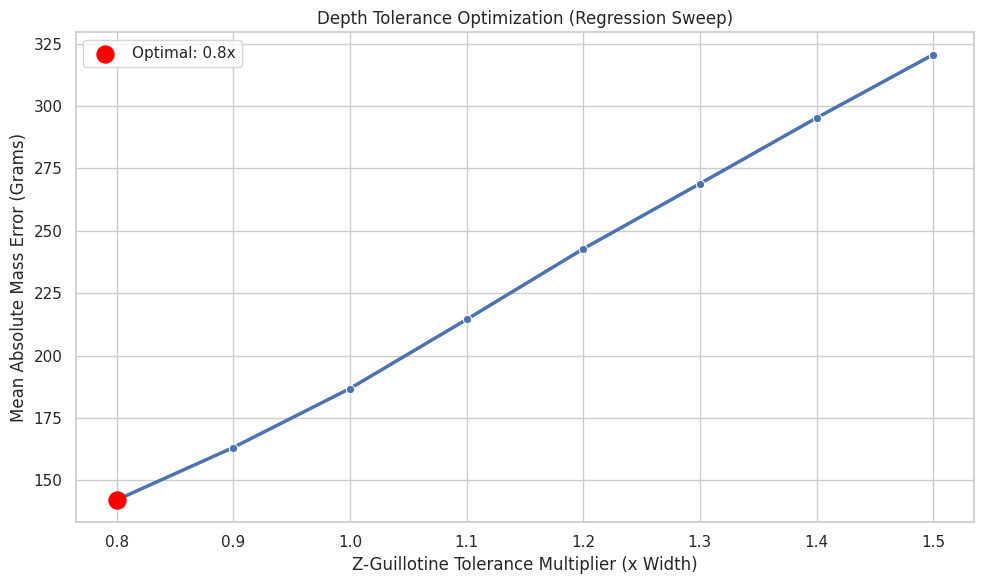

In [ ]:
# @title [Step 4] Spatial Calibration: U-Curve Visualization B
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = '/content/drive/MyDrive/AxisPowers/Thesis/MODEL'
LOG_PATH = os.path.join(PROJECT_ROOT, "sweep_metrics_log.csv")

if not os.path.exists(LOG_PATH):
	print("❌ Sweep log not found! Please run Step 4A first.")
else:
	# Load the data generated by Step 4A
	sweep_df = pd.read_csv(LOG_PATH)

	# Find the best multiplier for the graph marker
	best_idx = sweep_df['MAE_g'].idxmin()
	best_mult = sweep_df.loc[best_idx, 'Multiplier']
	min_mae = sweep_df.loc[best_idx, 'MAE_g']

	# --- PLOT THE U-CURVE ---
	sns.set_theme(style="whitegrid")
	plt.figure(figsize=(10, 6))
	sns.lineplot(data=sweep_df, x="Multiplier", y="MAE_g", marker="o", linewidth=2.5, color="b")

	# Highlight the minimum point
	plt.scatter([best_mult], [min_mae], color="red", s=150, zorder=5, label=f"Optimal: {best_mult}x")

	plt.title("Depth Tolerance Optimization (Regression Sweep)")
	plt.xlabel("Z-Guillotine Tolerance Multiplier (x Width)")
	plt.ylabel("Mean Absolute Mass Error (Grams)")
	plt.legend()
	plt.tight_layout()
	plt.show()

--- INITIATING EMPIRICAL SOLIDITY DASHBOARD ---

📊 STATISTICAL SUMMARY OF MANUAL MEASUREMENTS


,Object_ID,Mean_Solidity,Std_Deviation,Min_Solidity,Max_Solidity,Current_Baseline
0,CERAMIC_BOWL,0.1443,0.0182,0.1130,0.1687,0.1443
1,CERAMIC_CUP,0.1397,0.0374,0.0918,0.2205,0.1397
2,GLASS_BOTTLE,0.1830,0.0916,0.0685,0.2968,0.1830
3,GLASS_BOWL,0.1356,0.0000,0.1356,0.1356,0.1356
4,GLASS_CUP,0.1546,0.0753,0.0547,0.2840,0.1546
5,METAL_BOTTLE,0.1777,0.0146,0.1597,0.1948,0.1777
6,METAL_BOWL,0.0501,0.0134,0.0305,0.0651,0.0501
7,METAL_CUP,0.0502,0.0239,0.0256,0.1159,0.0502
8,PAPER_BOWL,0.0363,0.0000,0.0363,0.0363,0.0363
9,PAPER_CUP,0.0268,0.0089,0.0115,0.0565,0.0268


/tmp/ipykernel_8091/3196177245.py:65: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x="Object_ID", y="Solidity_Measurement", data=df, palette="pastel", width=0.6, showfliers=True)


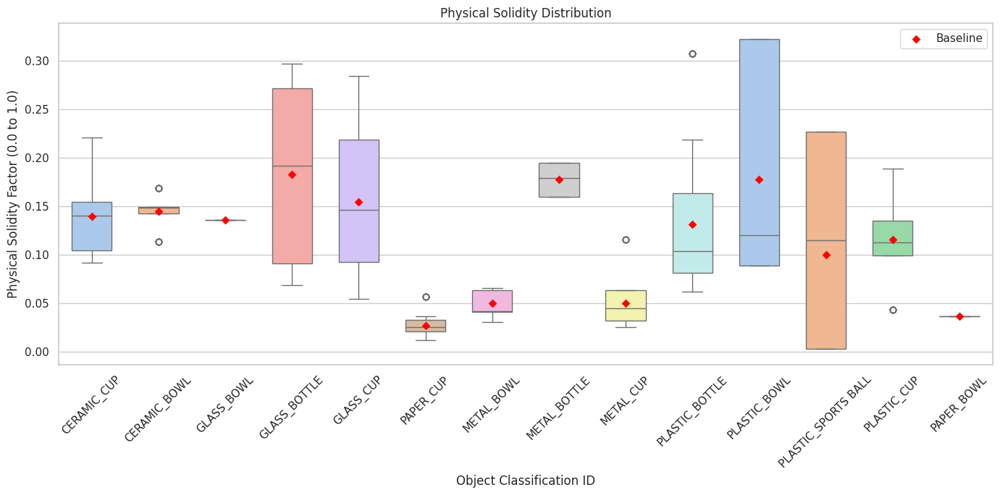

In [ ]:
# @title [Step 4] Manual Solidity Statistics & Dashboard
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = '/content/drive/MyDrive/AxisPowers/Thesis/MODEL'
# Point this to the CSV you filled out manually in Excel
COMPLETED_CSV_PATH = os.path.join(PROJECT_ROOT, "completed_solidity_measurements.csv")

print("--- INITIATING EMPIRICAL SOLIDITY DASHBOARD ---")

if not os.path.exists(COMPLETED_CSV_PATH):
	print(f"❌ Completed CSV not found at {COMPLETED_CSV_PATH}")
	print("Please ensure you have filled out your manual measurements and uploaded the file.")
else:
	# 1. Load your manually collected data
	df = pd.read_csv(COMPLETED_CSV_PATH)

	# Clean column names just in case Excel added hidden spaces during export
	df.columns = df.columns.str.strip()

	# Safety check to ensure the CSV format matches your Excel sheet headers
	if 'Solidity_Measurement' not in df.columns or 'Object_ID' not in df.columns:
		print("❌ Error: Missing required columns in CSV!")
		print(f"Found columns: {df.columns.tolist()}")
		print("Expected to find 'Object_ID' and 'Solidity_Measurement'. Check your Excel headers.")
	else:
		# Drop any rows where you might have forgotten to type a measurement
		df = df.dropna(subset=['Solidity_Measurement'])

		# Force the column to be numeric, turning accidental text (like "N/A") into NaNs, then drop them
		df['Solidity_Measurement'] = pd.to_numeric(df['Solidity_Measurement'], errors='coerce')
		df = df.dropna(subset=['Solidity_Measurement'])

		# 2. Fetch the Baseline values from Step 2 to compare
		def get_baseline(obj_id):
			try:
				# Assumes SOLIDITY_TABLE from Step 2 is loaded in memory
				return SOLIDITY_TABLE.get(obj_id, 0.10)
			except NameError:
				return 0.10 # Default to 0.10 if Step 2 hasn't been run yet

		df['Step_2_Baseline'] = df['Object_ID'].apply(get_baseline)

		# --- DISPLAY THE STATISTICAL BREAKDOWN TABLE ---
		print("\n📊 STATISTICAL SUMMARY OF MANUAL MEASUREMENTS")
		stats_df = df.groupby('Object_ID').agg(
			Mean_Solidity=('Solidity_Measurement', 'mean'),
			Std_Deviation=('Solidity_Measurement', 'std'),
			Min_Solidity=('Solidity_Measurement', 'min'),
			Max_Solidity=('Solidity_Measurement', 'max'),
			Current_Baseline=('Step_2_Baseline', 'first')
		).reset_index()

		format_dict = {"Mean_Solidity": "{:.4f}", "Std_Deviation": "{:.4f}", "Min_Solidity": "{:.4f}", "Max_Solidity": "{:.4f}", "Current_Baseline": "{:.4f}"}
		display(stats_df.style.set_properties(**{'text-align': 'left'}).format(format_dict))

		# --- PLOT THE BOX-AND-WHISKER (CANDLESTICK) CHART ---
		sns.set_theme(style="whitegrid")
		plt.figure(figsize=(14, 7))

		# The physical distribution of your manual measurements (The "Candlesticks")
		ax = sns.boxplot(x="Object_ID", y="Solidity_Measurement", data=df, palette="pastel", width=0.6, showfliers=True)

		# Overlay the Step 2 Baseline as distinct red diamond markers
		baseline_data = df.groupby("Object_ID")["Step_2_Baseline"].first().reset_index()
		sns.stripplot(x="Object_ID", y="Step_2_Baseline", data=baseline_data, color="red", marker="D", size=6, label="Baseline", ax=ax, jitter=False)

		plt.title("Physical Solidity Distribution")
		plt.xlabel("Object Classification ID")
		plt.ylabel("Physical Solidity Factor (0.0 to 1.0)")
		plt.xticks(rotation=45)

		# Clean up legend
		handles, labels = ax.get_legend_handles_labels()
		if handles:
			plt.legend(handles[-1:], labels[-1:], loc='upper right')

		plt.tight_layout()
		plt.show()

# **Deployment Testing**

In [ ]:
# @title [Step 5] The Engine
import math
import uuid
import open3d as o3d
import pandas as pd

# --- PANDAS 2.2+ COMPATIBILITY PATCH FOR NVIDIA RAPIDS ---
# Fixes the 'is_interval' AttributeError caused by new Pandas versions
if not hasattr(pd.api.types, 'is_interval'):
	pd.api.types.is_interval = pd.api.types.is_interval_dtype

import cv2
import numpy as np
import torch
import os
import json
import torchvision.transforms as T
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
from PIL import Image
from scipy.spatial import ConvexHull
import cuml # NVIDIA Rapids GPU Library

PROJECT_ROOT = '/content/drive/MyDrive/AxisPowers/Thesis/MODEL'
FEEDBACK_DIR = os.path.join(PROJECT_ROOT, "deployment_feedback")
MODEL_PATH = os.path.join(PROJECT_ROOT, "models", "material_model.pth")

# --- THE AUTOMATED CALIBRATION LOADER ---
CONFIG_PATH = os.path.join(PROJECT_ROOT, "calibration_config.json")

if os.path.exists(CONFIG_PATH):
	with open(CONFIG_PATH, "r") as f:
		config_data = json.load(f)
		OPTIMAL_DEPTH_MULTIPLIER = config_data.get("optimal_depth_multiplier", 1.1)
	print(f"⚙️ Auto-Loaded Calibrated Depth Multiplier: {OPTIMAL_DEPTH_MULTIPLIER}x")
else:
	OPTIMAL_DEPTH_MULTIPLIER = 1.1
	print("⚠️ Calibration config not found. Using default 1.1x fallback.")

# --- CAMERA INTRINSICS & STATIC BASELINE ---
CAMERA_FOCAL_LENGTH_MM = 28.0 # Standard Phone Camera Main Lens
CAMERA_SENSOR_WIDTH_MM = 27.0 # Standard Full-Frame Reference Width
STATIC_DISTANCE_MM = 200.0 # Hardcoded baseline distance
ACTIVE_LEARNING_THRESHOLD = 0.85

MATERIAL_LABELS = ["ceramic", "glass", "metal", "paper", "plastic"]

# Initialize Material Analyzer
material_cnn = mobilenet_v2(weights=MobileNet_V2_Weights.DEFAULT)
material_cnn.classifier = torch.nn.Sequential(
	torch.nn.Dropout(p=0.5),
	torch.nn.Linear(material_cnn.last_channel, 512),
	torch.nn.ReLU(),
	torch.nn.Dropout(p=0.3),
	torch.nn.Linear(512, len(MATERIAL_LABELS))
)
if os.path.exists(MODEL_PATH):
	material_cnn.load_state_dict(torch.load(MODEL_PATH, map_location=device))
material_cnn.to(device)
material_cnn.eval()
cnn_transforms = T.Compose([T.ToPILImage(), T.Resize((224, 224)), T.ToTensor(), T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])

def active_learning_autosave(img_rgb, bbox, mat, conf):
	if conf >= ACTIVE_LEARNING_THRESHOLD:
		x1, y1, x2, y2 = map(int, bbox)
		crop = img_rgb[max(0, y1):min(img_rgb.shape[0], y2), max(0, x1):min(img_rgb.shape[1], x2)]
		if crop.size > 0:
			mat_folder = os.path.join(FEEDBACK_DIR, mat)
			os.makedirs(mat_folder, exist_ok=True)
			save_path = os.path.join(mat_folder, f"learned_{uuid.uuid4().hex[:8]}.jpg")
			cv2.imwrite(save_path, cv2.cvtColor(crop, cv2.COLOR_RGB2BGR))
			return "Triggered (Saved)"
	return "Ignored (Low Conf)"

def classify_material(img_rgb, bbox):
	x1, y1, x2, y2 = map(int, bbox)
	crop = img_rgb[max(0, y1):min(img_rgb.shape[0], y2), max(0, x1):min(img_rgb.shape[1], x2)]
	if crop.size == 0: return "unknown", 0.0
	tensor = cnn_transforms(crop).unsqueeze(0).to(device)
	with torch.no_grad():
		probs = torch.nn.functional.softmax(material_cnn(tensor)[0], dim=0)
		idx = torch.argmax(probs).item()
		conf = probs[idx].item()
	return (MATERIAL_LABELS[idx], conf) if conf >= 0.45 else ("unknown", conf)

def get_angle(img_rgb, bbox):
	x1, y1, x2, y2 = map(int, bbox)
	crop = img_rgb[max(0, y1):min(img_rgb.shape[0], y2), max(0, x1):min(img_rgb.shape[1], x2)]
	if crop.size == 0: return 0
	gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)
	_, thresh = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
	cnts, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
	if cnts:
		rect = cv2.minAreaRect(max(cnts, key=cv2.contourArea))
		angle = rect[2]
		return abs(angle - 90 if angle > 45 else angle)
	return 0

def calc_spatial_metric(img_rgb, bbox, mask, img_w, depth_mult=OPTIMAL_DEPTH_MULTIPLIER):
	focal = (img_w * CAMERA_FOCAL_LENGTH_MM) / CAMERA_SENSOR_WIDTH_MM
	x1, y1, x2, y2 = map(int, bbox)

	# --- 1. THE X AND Y AXES (Unbreakable Pinhole Math) ---
	fusion_w = ((x2 - x1) * STATIC_DISTANCE_MM) / focal
	fusion_h = ((y2 - y1) * STATIC_DISTANCE_MM) / focal

	try:
		img_pil = Image.fromarray(img_rgb)
		with torch.no_grad():
			depth_numpy = zoe.infer_pil(img_pil)

		raw_depth_mm = depth_numpy * 1000.0
		roi_depth = raw_depth_mm[y1:y2, x1:x2]
		roi_mask = mask[y1:y2, x1:x2]

		kernel = np.ones((5, 5), np.uint8)
		roi_mask_eroded = cv2.erode(roi_mask, kernel, iterations=3)
		roi_depth_pruned = roi_depth * roi_mask_eroded

		valid_depths = roi_depth_pruned[roi_depth_pruned > 0]
		raw_median = np.median(valid_depths) if valid_depths.size > 0 else 1000.0

		visual_scale = STATIC_DISTANCE_MM / raw_median
		roi_depth_visual = roi_depth_pruned * visual_scale

		# --- 3. THE SAFETY NET (Z-Guillotine bounded by calibrated width) ---
		depth_tolerance = fusion_w * depth_mult
		depth_tolerance = max(depth_tolerance, 50.0)

		depth_filter_mask = (roi_depth_visual > (STATIC_DISTANCE_MM - depth_tolerance)) & (roi_depth_visual < (STATIC_DISTANCE_MM + depth_tolerance))
		roi_depth_clean = roi_depth_visual * depth_filter_mask

	except Exception as e:
		print(f"❌ ZoeDepth Error: {e}")
		fallback_d = fusion_w * 0.8
		return fusion_w, fusion_h, fallback_d, (fusion_w * fusion_h * fallback_d), STATIC_DISTANCE_MM, None, f"ERROR: ZoeDepth Failed ({str(e)})"

	try:
		intr = o3d.camera.PinholeCameraIntrinsic(int(x2-x1), int(y2-y1), focal, focal, (x2-x1)/2, (y2-y1)/2)

		rgbd = o3d.geometry.RGBDImage.create_from_color_and_depth(
			o3d.geometry.Image(np.ascontiguousarray(img_rgb[y1:y2, x1:x2])),
			o3d.geometry.Image(roi_depth_clean.astype(np.float32)),
			depth_scale=1.0,
			depth_trunc=5000.0,
			convert_rgb_to_intensity=False
		)

		pcd = o3d.geometry.PointCloud.create_from_rgbd_image(rgbd, intr)
		pcd = pcd.voxel_down_sample(voxel_size=3.0)

		# --- RAPIDS cuML GPU CLUSTERING ---
		# 1. Get the raw coordinates from Open3D
		core_points_raw = np.asarray(pcd.points)

		if len(core_points_raw) == 0:
			raise ValueError("Point cloud is empty.")

		# 2. Initialize the GPU-powered DBSCAN
		gpu_dbscan = cuml.cluster.DBSCAN(eps=15.0, min_samples=15)

		# 3. Blast the math through the T4 GPU instantly
		labels = gpu_dbscan.fit_predict(core_points_raw)

		# Ensure labels are a standard numpy array (handles cuDF/cupy types)
		if hasattr(labels, 'get'):
			labels = labels.get()
		else:
			labels = np.asarray(labels)

		max_label = labels.max()
		if max_label < 0:
			raise ValueError("DBSCAN found only noise.")

		# 4. Continue your pipeline as normal
		valid_labels = labels[labels >= 0]
		counts = np.bincount(valid_labels)
		largest_cluster_idx = np.argmax(counts)

		cluster_indices = np.where(labels == largest_cluster_idx)[0]
		pcd_core = pcd.select_by_index(cluster_indices)
		core_points = np.asarray(pcd_core.points)

		# --- 2. THE Z AXIS & VOLUME (True 3D Topography) ---
		obb = pcd_core.get_oriented_bounding_box()
		dims = sorted(obb.extent)
		fusion_d = float(dims[0])

		if len(core_points) < 4:
			raise ValueError("Not enough points for a volume hull.")

		hull = ConvexHull(core_points)
		fusion_vol = hull.volume

		return fusion_w, fusion_h, fusion_d, fusion_vol, STATIC_DISTANCE_MM, core_points, "Stable (True 3D)"

	except Exception as e:
		print(f"⚠️ 3D Topology Error: {e}. Outputting explicitly to Diagnostics Table.")
		fallback_d = fusion_w * 0.8
		return fusion_w, fusion_h, fallback_d, (fusion_w * fusion_h * fallback_d), STATIC_DISTANCE_MM, None, f"ERROR: {str(e)}"

def run_pipeline(img_path, is_deployment=False, sweep_mult=OPTIMAL_DEPTH_MULTIPLIER, override_mat=None, override_obj=None):
	img = cv2.imread(img_path)
	if img is None: return None, None
	img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
	h, w = img.shape[:2]

	results = yolo_model(img_rgb, verbose=False)
	if not results[0].boxes: return None, None

	img_cx, img_cy = w // 2, h // 2
	best_box = None
	min_dist = float('inf')
	best_idx = 0

	for i, box in enumerate(results[0].boxes):
		x1, y1, x2, y2 = box.xyxy[0].tolist()
		box_cx, box_cy = (x1 + x2) / 2, (y1 + y2) / 2
		dist = math.sqrt((box_cx - img_cx)**2 + (box_cy - img_cy)**2)

		if dist < min_dist:
			min_dist = dist
			best_box = box
			best_idx = i

	cat = results[0].names[int(best_box.cls[0])]
	conf = float(best_box.conf[0])
	bbox = best_box.xyxy[0].tolist()

	# --- OBJECT OVERRIDE LOGIC ---
	if override_obj is not None:
		cat = override_obj.upper()
		conf = 1.0 # Force confidence to 100% for Ground Truth

	mask = np.ones(img_rgb.shape[:2], dtype=np.float32)
	if results[0].masks is not None:
		mask_data = results[0].masks.data[best_idx].cpu().numpy()
		mask = cv2.resize(mask_data, (w, h), interpolation=cv2.INTER_NEAREST)

	mat, mat_conf = classify_material(img_rgb, bbox)

	# --- MATERIAL OVERRIDE LOGIC ---
	if override_mat is not None:
		mat = override_mat.lower()
		mat_conf = 1.0 # Force confidence to 100% for Ground Truth

	angle = get_angle(img_rgb, bbox)
	compliance = "Rigid" if mat in ["glass", "metal", "ceramic"] else "Semi-Compliant"

	w_mm, h_mm, d_mm, vol_mm3, dynamic_distance, pcd_points, topo_status = calc_spatial_metric(img_rgb, bbox, mask, w, sweep_mult)

	# --- 2D TRUE EDGE AREA CALCULATION ---
	x1, y1, x2, y2 = map(int, bbox)
	bbox_pixel_area = max(1, (x2 - x1) * (y2 - y1))
	bbox_mm_area = w_mm * h_mm

	if results[0].masks is not None:
		mm2_per_pixel = bbox_mm_area / bbox_pixel_area
		roi_mask = mask[y1:y2, x1:x2]
		true_pixel_area = np.count_nonzero(roi_mask)
		area_mm2 = true_pixel_area * mm2_per_pixel
	else:
		area_mm2 = bbox_mm_area

	# --- UNIFIED PHYSICS ---
	object_id = f"{mat.upper()}_{cat.upper().replace(' ', '_')}"

	solidity = SOLIDITY_TABLE.get(object_id, 0.10)
	density_g_mm3 = MATERIAL_DENSITY.get(object_id, 0.001)
	dynamic_friction = FRICTION_LIBRARY.get(mat.lower(), 0.5)

	# NATIVE MATH: mm^3 * g/mm^3 * % = g
	mass_g = vol_mm3 * density_g_mm3 * solidity

	# --- THEORETICAL CONTROL KINEMATICS ---
	strategy, wrist, safety = determine_grasp_strategy((h_mm, w_mm, d_mm), angle, compliance)
	slip_n, torque_nm = calculate_forces(mass_g, dynamic_friction, dynamic_distance)

	learning_status = "N/A (Eval Mode)"
	if is_deployment and mat != "unknown":
		learning_status = active_learning_autosave(img_rgb, bbox, mat, mat_conf)

	raw_data = {"width": w_mm, "mass": mass_g, "mat": mat, "cat": cat, "bbox": bbox, "mask": mask, "img": img_rgb, "points": pcd_points, "area_mm2": area_mm2, "vol": vol_mm3, "solidity": solidity, "density": density_g_mm3, "object_id": object_id}

	data = [
		("1. Semantic", "Object ID", object_id),
		("1. Semantic", "Object Confidence", f"{conf*100:.1f}%"),
		("1. Semantic", "Material Confidence", f"{mat_conf*100:.1f}%"),
		("1. Semantic", "Surface Material", mat.title()),
		("1. Semantic", "Compliance Tag", compliance),
		("2. Spatial", "Topology Status", topo_status),
		("2. Spatial", "True Hybrid Bounds", f"{w_mm:.1f} x {h_mm:.1f} x {d_mm:.1f} mm"),
		("2. Spatial", "Traced Organic Area", f"{area_mm2:.1f} mm²"),
		("2. Spatial", "True Topography Volume", f"{vol_mm3:.0f} mm³"),
		("3. Physics", "Assumed Density", f"{density_g_mm3:.2e} g/mm³"),
		("3. Physics", "Solidity Factor", f"{solidity*100:.2f}%"),
		("3. Physics", "Estimated Mass", f"{mass_g:.1f} g"),
		("4. Control", "Grip Strategy", strategy),
		("4. Control", "Wrist Command", f"{wrist}°"),
		("4. Control", "Slip Threshold", f"{slip_n:.2f} N"),
		("4. Control", "Lift Torque", f"{torque_nm:.3f} Nm"),
		("5. State", "Active Learning", learning_status)
	]
	phases, metrics, values = zip(*data)
	df = pd.DataFrame(values, index=pd.MultiIndex.from_arrays([phases, metrics], names=["Phase", "Metric"]), columns=["Value"])

	return raw_data, df

print("✅ Engine Initialized.")

⚙️ Auto-Loaded Calibrated Depth Multiplier: 0.8x
✅ Engine Initialized.


--- INITIATING PRE-DEPLOYMENT TEST ---

📡 Field View: test_001.jpg



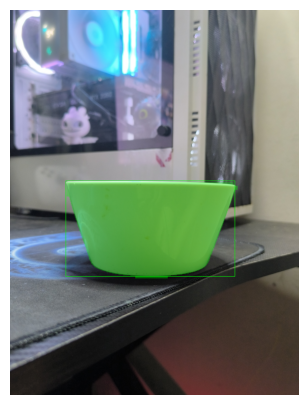


📡 Field View: test_002.jpg



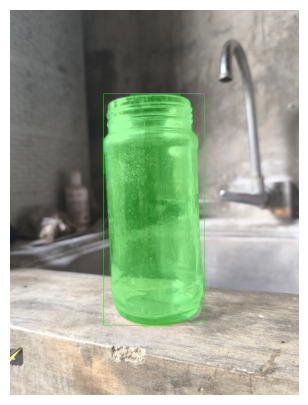


📡 Field View: test_003.jpg



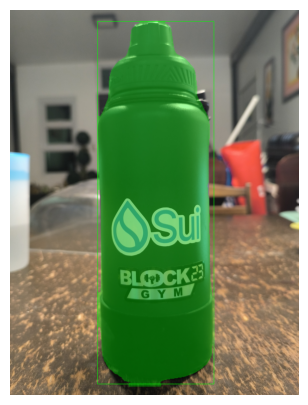


📡 Field View: test_004.jpg



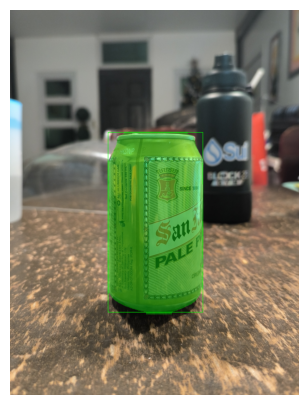


📡 Field View: test_005.jpg



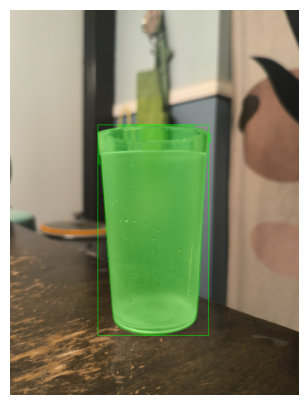


📡 Field View: test_006.jpg



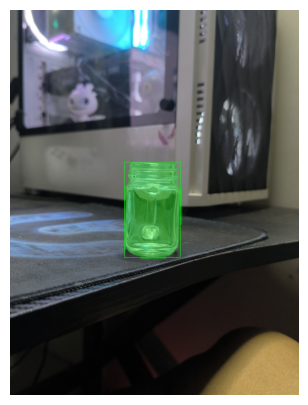


📡 Field View: test_007.jpg



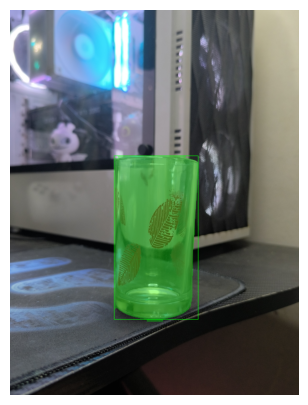


📡 Field View: test_008.jpg



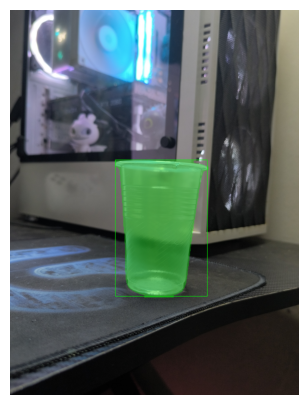


📡 Field View: test_009.jpg



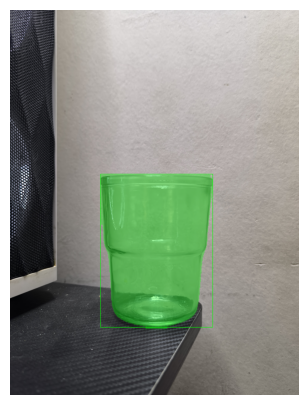


📡 Field View: test_010.jpg



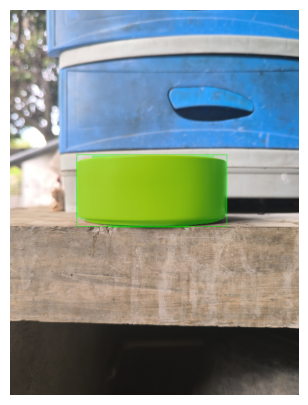


📡 Field View: test_011.jpg



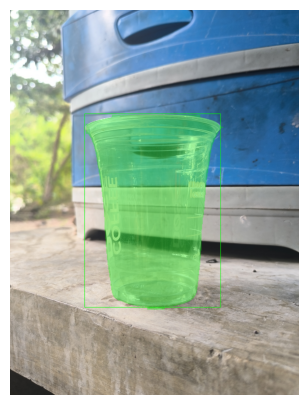


📡 Field View: test_012.jpg



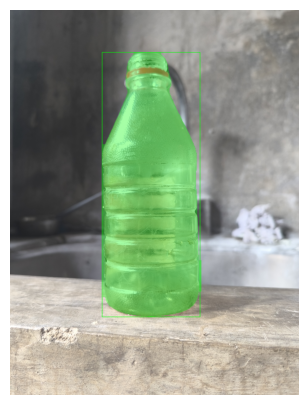


📡 Field View: test_013.jpg



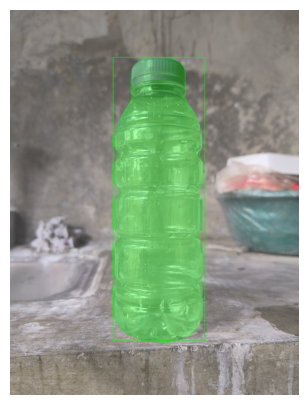


📡 Field View: test_014.jpg



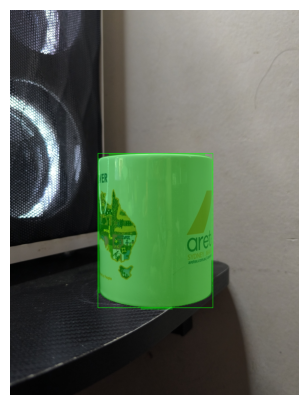


📡 Field View: test_015.jpg



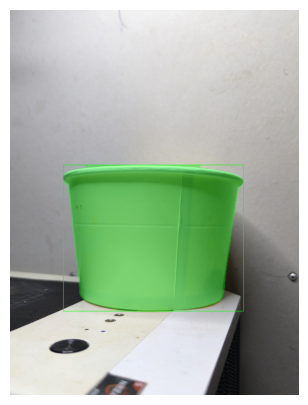


📡 Field View: test_016.jpg



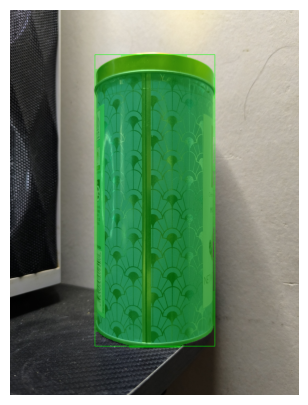


📡 Field View: test_017.jpg



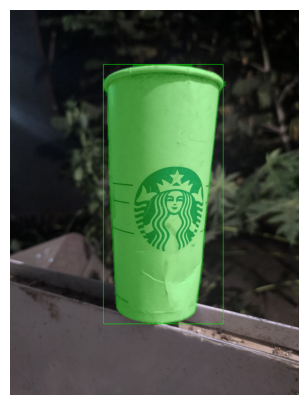


📡 Field View: test_018.jpg



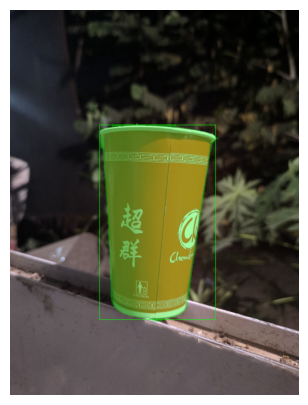


📡 Field View: test_019.jpg



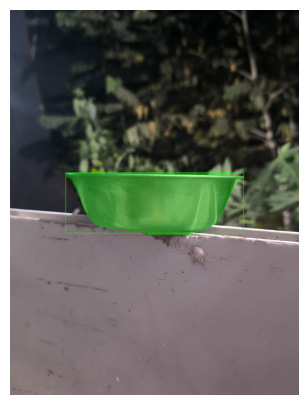


📡 Field View: test_020.jpg



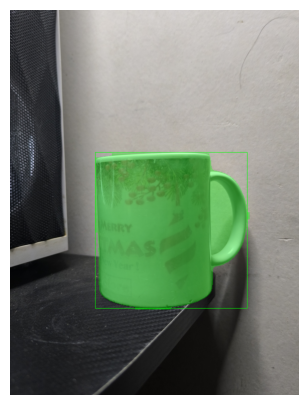


📡 Field View: test_021.jpg



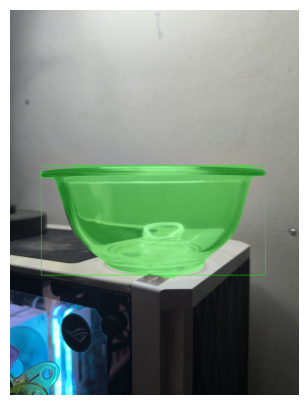


📡 Field View: test_022.jpg



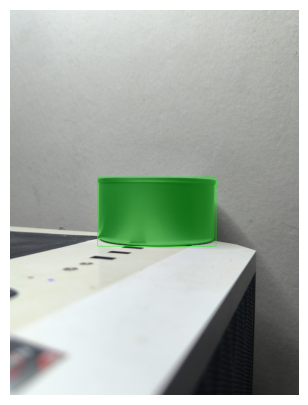


📡 Field View: test_023.jpg



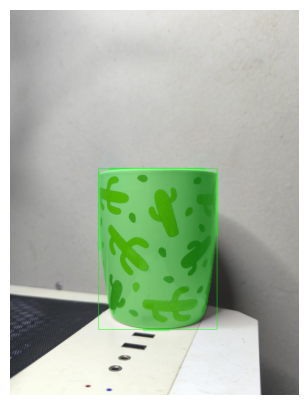


📡 Field View: test_024.jpg



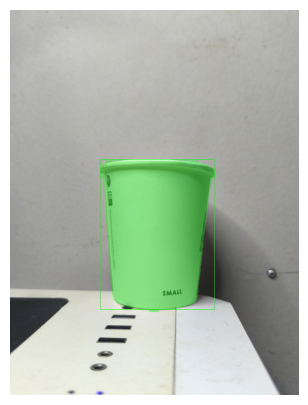


📡 Field View: test_025.jpg



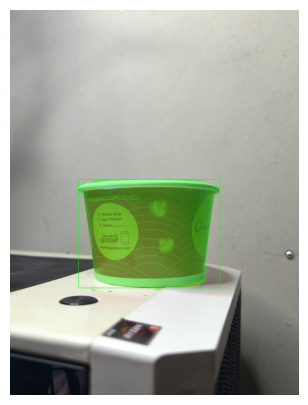

In [ ]:
# @title [Step 6] Pre-Deployment Testing (Visual Verification)
import os
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import plotly.graph_objects as go
import base64
from io import BytesIO
import numpy as np
from scipy.spatial import ConvexHull

DEPLOY_DIR = os.path.join(PROJECT_ROOT, "dataset_evaluation")
print("--- INITIATING PRE-DEPLOYMENT TEST ---")

deploy_files = sorted([f for f in os.listdir(DEPLOY_DIR) if f.endswith(('.jpg', '.png'))])

if not deploy_files:
	print(f"❌ No images found in '{DEPLOY_DIR}'!")
else:
	for filename in deploy_files:
		print(f"\n📡 Field View: {filename}")
		raw, df = run_pipeline(os.path.join(DEPLOY_DIR, filename), is_deployment=True)

		if df is not None and raw is not None:
			img_rgb = raw.get("img")
			bbox = raw.get("bbox")
			cat = raw.get("cat", "Object")
			mat = raw.get("mat", "Unknown")
			pcd_points = raw.get("points")
			area_mm2 = raw.get("area_mm2", 0.0)
			mask_array = raw.get("mask")

			img_2d_html = ""
			fig_3d_html = ""
			fig_hull_html = ""
			pixel_area = 0

			# --- 2D VISUALIZATION: OBB + ORGANIC AREA MAPPING ---
			if img_rgb is not None and bbox is not None:
				plt.figure(figsize=(5, 5))

				overlay = img_rgb.copy()
				x1, y1, x2, y2 = map(int, bbox)

				# 1. Check for valid organic mask and map the area
				if mask_array is not None and np.any(mask_array == 0):
					# Calculate raw pixel area from the mask ROI
					roi_mask = mask_array[y1:y2, x1:x2]
					pixel_area = np.count_nonzero(roi_mask)

					mask_uint8 = (mask_array * 255).astype(np.uint8)
					contours, _ = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

					# Fill the organic shape on the overlay
					cv2.drawContours(overlay, contours, -1, (0, 255, 0), -1)
					alpha = 0.35
					cv2.addWeighted(overlay, alpha, img_rgb, 1 - alpha, 0, img_rgb)
				else:
					# Fallback: calculate full OBB pixel area and fill it
					pixel_area = max(1, (x2 - x1) * (y2 - y1))
					cv2.rectangle(overlay, (x1, y1), (x2, y2), (0, 255, 0), -1)
					alpha = 0.35
					cv2.addWeighted(overlay, alpha, img_rgb, 1 - alpha, 0, img_rgb)

				# 2. Draw the strict OBB (Bounding Box) on top
				cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (0, 255, 0), 3)

				plt.imshow(img_rgb)
				plt.axis('off')

				buffer = BytesIO()
				plt.savefig(buffer, format='png', bbox_inches='tight', pad_inches=0.1)
				plt.close()
				buffer.seek(0)

				image_base64 = base64.b64encode(buffer.read()).decode('utf-8')
				img_2d_html = f'<img src="data:image/png;base64,{image_base64}" style="width: 100%; max-width: 300px; height: auto;">'

			# --- 3D INTERACTIVE VISUALIZATIONS ---
			if pcd_points is not None and len(pcd_points) > 3:
				max_points = 5000
				if len(pcd_points) > max_points:
					indices = np.random.choice(len(pcd_points), max_points, replace=False)
					display_points = pcd_points[indices]
				else:
					display_points = pcd_points

				# 1. Raw Point Cloud
				fig_points = go.Figure(data=[go.Scatter3d(
					x=display_points[:, 0],
					y=display_points[:, 1],
					z=display_points[:, 2],
					mode='markers',
					marker=dict(size=2, color=display_points[:, 2], colorscale='Viridis', opacity=0.8)
				)])

				fig_points.update_layout(
					scene=dict(
						xaxis_title='X (mm)',
						yaxis_title='Y (mm)',
						zaxis_title='Z (mm)'
					),
					margin=dict(l=0, r=0, b=0, t=0),
					height=350,
					width=None
				)
				fig_3d_html = fig_points.to_html(include_plotlyjs='cdn', full_html=False)

				# 2. Convex Hull Mesh
				try:
					hull = ConvexHull(pcd_points)
					fig_hull = go.Figure(data=[go.Mesh3d(
						x=pcd_points[:, 0],
						y=pcd_points[:, 1],
						z=pcd_points[:, 2],
						i=hull.simplices[:, 0],
						j=hull.simplices[:, 1],
						k=hull.simplices[:, 2],
						color='lightblue',
						opacity=0.60,
						alphahull=0
					)])

					fig_hull.update_layout(
						scene=dict(
							xaxis_title='X (mm)',
							yaxis_title='Y (mm)',
							zaxis_title='Z (mm)'
						),
						margin=dict(l=0, r=0, b=0, t=0),
						height=350,
						width=None
					)
					fig_hull_html = fig_hull.to_html(include_plotlyjs='cdn', full_html=False)
				except Exception as e:
					fig_hull_html = f"<div style='color:red;'>Hull generation failed: {str(e)}</div>"

			# --- RENDER THREE-COLUMN PRESENTATION ---
			combined_presentation = f"""
			<div style="display: flex; flex-direction: row; justify-content: space-between; align-items: stretch; gap: 15px; width: 100%; border: 2px solid #333; padding: 15px; background-color: #f9f9f9; border-radius: 10px;">
				<div style="flex: 1; text-align: center; display: flex; flex-direction: column;">
					<h3 style="margin-top: 0; color: #000;">1. 2D Detection</h3>
					<div style="flex-grow: 1; display: flex; flex-direction: column; align-items: center; justify-content: center;">
						{img_2d_html}
						<div style="margin-top: 10px; padding: 5px 10px; background-color: #e0e0e0; border-radius: 5px; font-weight: bold; color: #333; text-align: center;">
							Pixel Area: {pixel_area} px<br>
							Organic Area: {area_mm2:.1f} mm²
						</div>
					</div>
				</div>
				<div style="flex: 1; text-align: center; display: flex; flex-direction: column;">
					<h3 style="margin-top: 0; color: #000;">2. 3D Point Cloud</h3>
					<div style="border: 1px solid #ddd; padding: 5px; background: white; flex-grow: 1;">
						{fig_3d_html}
					</div>
				</div>
				<div style="flex: 1; text-align: center; display: flex; flex-direction: column;">
					<h3 style="margin-top: 0; color: #000;">3. Convex Hull Mesh</h3>
					<div style="border: 1px solid #ddd; padding: 5px; background: white; flex-grow: 1;">
						{fig_hull_html}
					</div>
				</div>
			</div>
			<br>
			"""
			display(HTML(combined_presentation))

			# --- METRICS DATAFRAME ---
			styled = df.style.set_properties(**{'text-align': 'left'}).set_table_styles([
				dict(selector='th', props=[('text-align', 'left'), ('font-weight', 'bold')]),
				dict(selector='td', props=[('text-align', 'left')])
			])
			display(styled)
			print("=" * 120)

# **Model Evaluation**

In [ ]:
# @title [Step 7] Model Evaluation (Ground Truth Benchmarking)
import os
import numpy as np
import pandas as pd
from IPython.display import display

EVAL_DIR = os.path.join(PROJECT_ROOT, "dataset_evaluation")
CSV_PATH = os.path.join(PROJECT_ROOT, "evaluation_ground_truth.csv")

print("--- INITIATING CONTROLLED EVALUATION ---")
if not os.path.exists(CSV_PATH):
	print("❌ Ground truth CSV not found! Upload evaluation_ground_truth.csv to the ROOT.")
else:
	gt_df = pd.read_csv(CSV_PATH, index_col="Image_ID")

	# --- NON-PARAMETRIC MAPE STABILIZER (The 'Box' of Box-and-Whiskers) ---
	q1_mass = gt_df["True_Mass_g"].quantile(0.25)
	q3_mass = gt_df["True_Mass_g"].quantile(0.75)
	SAFE_MARGIN_G = q3_mass - q1_mass # The Interquartile Range (IQR)

	print(f"📊 Non-Parametric Tolerance Calculated: {SAFE_MARGIN_G:.1f}g (Based on IQR)")

	results = []
	matches = 0

	for filename in sorted(os.listdir(EVAL_DIR)):
		if filename in gt_df.index:
			img_path = os.path.join(EVAL_DIR, filename)
			true_mat = str(gt_df.loc[filename, "Material"]).lower()
			true_w = float(gt_df.loc[filename, "True_Width_mm"])

			# NATIVE GRAMS
			true_mass_g = float(gt_df.loc[filename, "True_Mass_g"])

			raw, _ = run_pipeline(img_path, is_deployment=False)

			if raw:
				pred_mat = raw["mat"]
				pred_w = raw["width"]
				pred_mass_g = raw["mass"] # Raw mass from Step 5 is in grams

				# --- EXTRACT AREA & PHYSICS METRICS ---
				pred_area_mm2 = raw.get("area_mm2", 0.0)
				pred_vol = raw.get("vol", 0.0)
				pred_solidity = raw.get("solidity", 0.0)
				pred_density = raw.get("density", 0.0)
				object_id = raw.get("object_id", "UNKNOWN")

				mask_array = raw.get("mask")
				bbox = raw.get("bbox")

				pixel_area = 0
				if bbox is not None:
					x1, y1, x2, y2 = map(int, bbox)
					if mask_array is not None and np.any(mask_array == 0):
						roi_mask = mask_array[y1:y2, x1:x2]
						pixel_area = np.count_nonzero(roi_mask)
					else:
						pixel_area = max(1, (x2 - x1) * (y2 - y1))

				if pred_mat == true_mat:
					matches += 1

				w_err_mm = abs(true_w - pred_w)

				# --- MASS ERROR CALCULATIONS (Safely Bounded by the IQR) ---
				mass_err_g = abs(true_mass_g - pred_mass_g)
				effective_denominator = max(true_mass_g, SAFE_MARGIN_G)
				mass_err_pct = (mass_err_g / effective_denominator) * 100

				# 1. TRANSPARENT COMPUTATION: Compiling row-by-row data
				row_data = {
					"Image": filename,
					"Object ID": object_id,
					"True Mat": true_mat.title(),
					"Pred Mat": pred_mat.title(),
					"True W (mm)": true_w,
					"Pred W (mm)": round(pred_w, 2),
					"W Error (mm)": round(w_err_mm, 2),
					"Area (px)": pixel_area,
					"Area (mm^2)": round(pred_area_mm2, 2),
					"Volume (mm^3)": pred_vol,
					"Solidity": pred_solidity,
					"Density (g/mm^3)": pred_density,
					"True Mass (g)": true_mass_g,
					"Pred Mass (g)": round(pred_mass_g, 2),
					"Mass Error (g)": round(mass_err_g, 2),
					"Mass Error (%)": round(mass_err_pct, 2)
				}

				results.append(row_data)

	if results:
		results_df = pd.DataFrame(results)

		# Pre-calculate the residual mass here so it is instantly ready for Step 8
		results_df["Residual Mass (g)"] = results_df["Pred Mass (g)"] - results_df["True Mass (g)"]

		# --- 3. STATISTICAL ROBUSTNESS ---
		mean_w_err = results_df["W Error (mm)"].mean()
		std_w_err = results_df["W Error (mm)"].std()

		# Calculate Mean Absolute Error (MAE) and MAPE natively in Grams
		mean_mass_err_g = results_df["Mass Error (g)"].mean()
		mean_mass_err_pct = results_df["Mass Error (%)"].mean()
		std_mass_err_pct = results_df["Mass Error (%)"].std()

		print(f"✅ Model Evaluation Complete!")

--- INITIATING CONTROLLED EVALUATION ---
📊 Non-Parametric Tolerance Calculated: 196.0g (Based on IQR)
✅ Model Evaluation Complete!


📊 Generating Visualizations and Data Tables from Memory...

        THESIS CHAPTER 4 METRICS
🎯 Semantic Accuracy:  64.0%
📏 Spatial Error (MAE): 9.70 mm ± 9.28 mm
⚖️ Mass Error (MAE):    134.7 grams
⚖️ Mass Error (MAPE):   49.34% ± 50.56% *

--- IMAGE-BY-IMAGE COMPUTATION BREAKDOWN ---


,Image,Object ID,True Mat,Pred Mat,Area (px),Area (mm^2),True W (mm),Pred W (mm),W Error (mm),True Mass (g),Pred Mass (g),Mass Error (g),Mass Error (%),Residual Mass (g)
0,test_001.jpg,CERAMIC_BOWL,Ceramic,Ceramic,1462077,5807.63,138.00,112.82,25.18,173.00,158.72,14.28,7.29,-14.28
1,test_002.jpg,GLASS_BOTTLE,Glass,Glass,2298779,9131.16,70.00,67.31,2.69,97.00,242.20,145.20,74.08,145.20
2,test_003.jpg,PLASTIC_BOTTLE,Metal,Plastic,3983456,15822.99,93.00,77.65,15.35,741.00,214.81,526.19,71.01,-526.19
3,test_004.jpg,UNKNOWN_BOTTLE,Metal,Unknown,1809702,7188.46,67.00,63.28,3.72,217.00,41.23,175.77,81.00,-175.77
4,test_005.jpg,PLASTIC_CUP,Plastic,Plastic,2248389,8931.00,73.00,73.80,0.80,52.00,62.06,10.06,5.13,10.06
5,test_006.jpg,GLASS_BOTTLE,Glass,Glass,556915,2212.17,37.00,37.31,0.31,80.00,50.09,29.91,15.26,-29.91
6,test_007.jpg,GLASS_CUP,Glass,Glass,1427789,5671.43,62.00,56.03,5.97,68.00,101.83,33.83,17.26,33.83
7,test_008.jpg,PLASTIC_CUP,Plastic,Plastic,1062385,4219.98,72.00,61.39,10.61,29.00,27.21,1.79,0.91,-1.79
8,test_009.jpg,GLASS_CUP,Glass,Glass,1644805,6533.46,90.00,74.87,15.13,94.00,158.64,64.64,32.98,64.64
9,test_010.jpg,CERAMIC_BOWL,Ceramic,Ceramic,1146108,4552.54,131.00,100.15,30.85,406.00,143.85,262.15,64.57,-262.15



--- INTERNAL PHYSICS ENGINE METRICS ---


,Image,Object ID,Pred Mat,Area (px),Area (mm^2),Volume (mm^3),Solidity,Density (g/mm^3),Pred Mass (g)
0,test_001.jpg,CERAMIC_BOWL,Ceramic,1462077,5807.63,458297,0.14,2.40e-03,158.72
1,test_002.jpg,GLASS_BOTTLE,Glass,2298779,9131.16,529404,0.18,2.50e-03,242.20
2,test_003.jpg,PLASTIC_BOTTLE,Plastic,3983456,15822.99,1184638,0.13,1.38e-03,214.81
3,test_004.jpg,UNKNOWN_BOTTLE,Unknown,1809702,7188.46,412275,0.10,1.00e-03,41.23
4,test_005.jpg,PLASTIC_CUP,Plastic,2248389,8931.00,595943,0.12,9.00e-04,62.06
5,test_006.jpg,GLASS_BOTTLE,Glass,556915,2212.17,109476,0.18,2.50e-03,50.09
6,test_007.jpg,GLASS_CUP,Glass,1427789,5671.43,274451,0.15,2.40e-03,101.83
7,test_008.jpg,PLASTIC_CUP,Plastic,1062385,4219.98,261329,0.12,9.00e-04,27.21
8,test_009.jpg,GLASS_CUP,Glass,1644805,6533.46,427551,0.15,2.40e-03,158.64
9,test_010.jpg,CERAMIC_BOWL,Ceramic,1146108,4552.54,415357,0.14,2.40e-03,143.85



--- PERFORMANCE BY MATERIAL CLASS ---


,True Mat,Count,Semantic_Accuracy,Avg_W_Error_mm,Avg_Mass_Err_g,Avg_Mass_Err_pct
0,Ceramic,5,80.00,18.14,146.13,43.06
1,Glass,5,100.00,11.31,128.97,41.62
2,Metal,5,20.00,7.05,159.30,40.05
3,Paper,5,60.00,6.83,107.75,54.98
4,Plastic,5,60.00,5.18,131.33,67.00


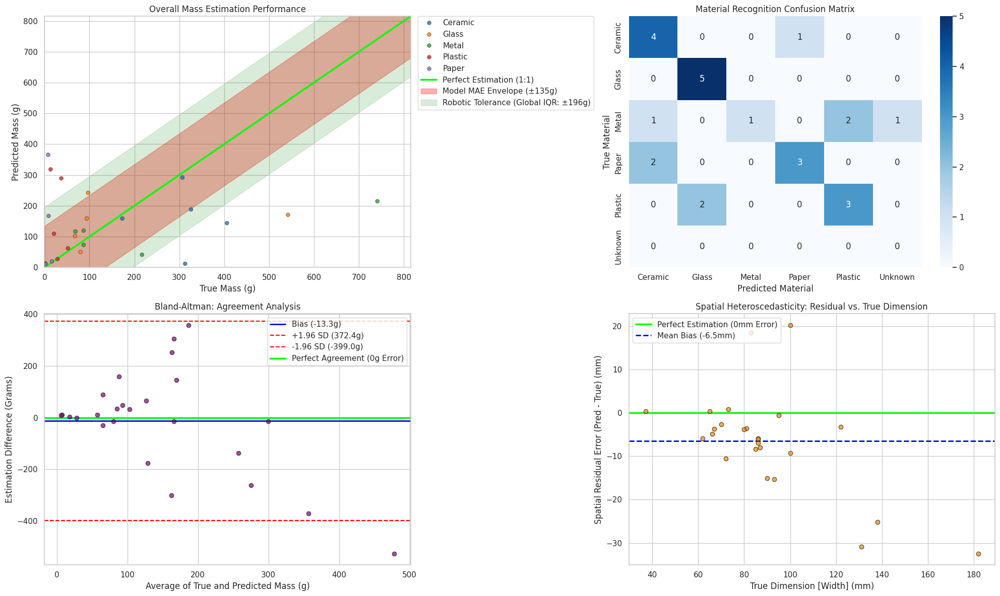

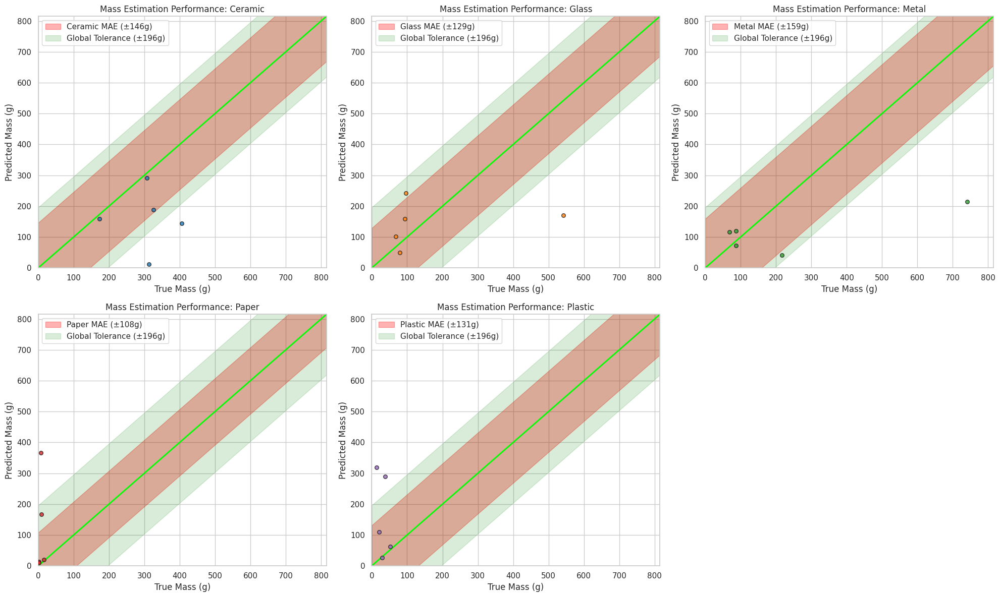

In [ ]:
# @title [Step 8] Thesis Visualizations & Dashboards
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np
from IPython.display import display

# --- SAFETY CHECK ---
if 'results_df' not in locals() or results_df.empty:
	print("❌ Error: Evaluation data not found! Please run Step 7 first to process the images.")
else:
	print("📊 Generating Visualizations and Data Tables from Memory...")

	# --- RECALCULATE METRICS FROM DATAFRAME ---
	results_df["Match"] = results_df["True Mat"].str.lower() == results_df["Pred Mat"].str.lower()

	matches = results_df["Match"].sum()
	total_results = len(results_df)

	mean_w_err = results_df["W Error (mm)"].mean()
	std_w_err = results_df["W Error (mm)"].std()

	mean_mass_err_g = results_df["Mass Error (g)"].mean()
	mean_mass_err_pct = results_df["Mass Error (%)"].mean()
	std_mass_err_pct = results_df["Mass Error (%)"].std()

	# --- 1. THESIS METRICS PRINTOUT ---
	print("\n==========================================")
	print("        THESIS CHAPTER 4 METRICS")
	print("==========================================")
	print(f"🎯 Semantic Accuracy:  {(matches / total_results) * 100:.1f}%")
	print(f"📏 Spatial Error (MAE): {mean_w_err:.2f} mm ± {std_w_err:.2f} mm")
	print(f"⚖️ Mass Error (MAE):    {mean_mass_err_g:.1f} grams")
	print(f"⚖️ Mass Error (MAPE):   {mean_mass_err_pct:.2f}% ± {std_mass_err_pct:.2f}% *")
	print("==========================================\n")

	# --- 2. TRANSPARENT COMPUTATION DATA TABLE ---
	print("--- IMAGE-BY-IMAGE COMPUTATION BREAKDOWN ---")

	base_cols = [col for col in results_df.columns if col != "Match"]

	desired_order = [
		"Image", "Object ID", "True Mat", "Pred Mat",
		"Area (px)", "Area (mm^2)",
		"True W (mm)", "Pred W (mm)", "W Error (mm)",
		"True Mass (g)", "Pred Mass (g)", "Mass Error (g)", "Mass Error (%)",
		"Residual Mass (g)", "Target Force (N)", "Grasp Safety"
	]

	final_cols = [col for col in desired_order if col in base_cols]

	for col in base_cols:
		if col not in final_cols and col not in ["Volume (mm^3)", "Solidity", "Density (g/mm^3)"]:
			final_cols.append(col)

	display_df = results_df[final_cols]

	format_dict = {
		"Area (px)": "{:.0f}",
		"Area (mm^2)": "{:.2f}",
		"True W (mm)": "{:.2f}",
		"Pred W (mm)": "{:.2f}",
		"W Error (mm)": "{:.2f}",
		"True Mass (g)": "{:.2f}",
		"Pred Mass (g)": "{:.2f}",
		"Mass Error (g)": "{:.2f}",
		"Mass Error (%)": "{:.2f}",
		"Residual Mass (g)": "{:.2f}",
		"Target Force (N)": "{:.2f}"
	}

	styled_df = display_df.style.set_properties(**{'text-align': 'left'}).format(format_dict)
	display(styled_df)

	# --- 3. PHYSICS ENGINE DEEP-DIVE TABLE ---
	print("\n--- INTERNAL PHYSICS ENGINE METRICS ---")
	physics_cols = [
		"Image", "Object ID", "Pred Mat", "Area (px)", "Area (mm^2)",
		"Volume (mm^3)", "Solidity", "Density (g/mm^3)", "Pred Mass (g)"
	]

	valid_physics_cols = [c for c in physics_cols if c in results_df.columns]
	physics_df = results_df[valid_physics_cols]

	physics_format = {
		"Area (px)": "{:.0f}",
		"Area (mm^2)": "{:.2f}",
		"Volume (mm^3)": "{:.0f}",
		"Solidity": "{:.2f}",
		"Density (g/mm^3)": "{:.2e}",
		"Pred Mass (g)": "{:.2f}"
	}

	styled_physics = physics_df.style.set_properties(**{'text-align': 'left'}).format(physics_format).set_table_styles([
		dict(selector='th', props=[('text-align', 'left'), ('font-weight', 'bold')]),
		dict(selector='td', props=[('text-align', 'left')])
	])
	display(styled_physics)

	# --- 4. MATERIAL-STRATIFIED ANALYSIS ---
	print("\n--- PERFORMANCE BY MATERIAL CLASS ---")
	stratified_df = results_df.groupby("True Mat").agg(
		Count=("Image", "count"),
		Semantic_Accuracy=("Match", lambda x: x.mean() * 100),
		Avg_W_Error_mm=("W Error (mm)", "mean"),
		Avg_Mass_Err_g=("Mass Error (g)", "mean"),
		Avg_Mass_Err_pct=("Mass Error (%)", "mean")
	).reset_index()

	stratified_format = {
		"Semantic_Accuracy": "{:.2f}",
		"Avg_W_Error_mm": "{:.2f}",
		"Avg_Mass_Err_g": "{:.2f}",
		"Avg_Mass_Err_pct": "{:.2f}"
	}

	display(stratified_df.style.format(stratified_format).set_table_styles([
		dict(selector='th', props=[('text-align', 'left'), ('font-weight', 'bold')]),
		dict(selector='td', props=[('text-align', 'left')])
	]))

	# --- 5. ACADEMIC VISUALIZATIONS ---
	sns.set_theme(style="whitegrid")

	fig, axes = plt.subplots(2, 2, figsize=(20, 12))

	# ---------------------------------------------------------
	# Graph A: Correlation Scatter Plot
	# ---------------------------------------------------------
	q1_mass = results_df["True Mass (g)"].quantile(0.25)
	q3_mass = results_df["True Mass (g)"].quantile(0.75)
	iqr_safety_margin = q3_mass - q1_mass

	max_mass = max(results_df["True Mass (g)"].max(), results_df["Pred Mass (g)"].max()) * 1.1
	x_vals = np.linspace(0, max_mass, 100)

	sns.scatterplot(
		data=results_df, x="True Mass (g)", y="Pred Mass (g)",
		hue="True Mat", palette="tab10", edgecolor='k', alpha=0.8,
		s=30, ax=axes[0, 0], zorder=5
	)

	axes[0, 0].plot(x_vals, x_vals, color='lime', linestyle='-', linewidth=2.5, label='Perfect Estimation (1:1)')

	axes[0, 0].fill_between(x_vals, x_vals - mean_mass_err_g, x_vals + mean_mass_err_g,
		color='red', alpha=0.3, label=f'Model MAE Envelope (±{mean_mass_err_g:.0f}g)')

	axes[0, 0].fill_between(x_vals, x_vals - iqr_safety_margin, x_vals + iqr_safety_margin,
		color='green', alpha=0.15, label=f'Robotic Tolerance (Global IQR: ±{iqr_safety_margin:.0f}g)')

	axes[0, 0].set_title('Overall Mass Estimation Performance')
	axes[0, 0].set_xlabel('True Mass (g)')
	axes[0, 0].set_ylabel('Predicted Mass (g)')
	axes[0, 0].set_xlim(0, max_mass)
	axes[0, 0].set_ylim(0, max_mass)

	# Fix legend duplication from seaborn + matplotlib
	handles, labels = axes[0, 0].get_legend_handles_labels()
	axes[0, 0].legend(handles=handles, labels=labels, loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0.)

	# ---------------------------------------------------------
	# Graph B: Confusion Matrix
	# ---------------------------------------------------------
	labels = sorted(list(set(results_df["True Mat"].tolist() + results_df["Pred Mat"].tolist())))
	cm = confusion_matrix(results_df["True Mat"], results_df["Pred Mat"], labels=labels)
	sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axes[0, 1])
	axes[0, 1].set_title('Material Recognition Confusion Matrix')
	axes[0, 1].set_xlabel('Predicted Material')
	axes[0, 1].set_ylabel('True Material')

	# ---------------------------------------------------------
	# Graph C: Bland-Altman Plot
	# ---------------------------------------------------------
	means = (results_df["Pred Mass (g)"] + results_df["True Mass (g)"]) / 2
	diffs = results_df["Pred Mass (g)"] - results_df["True Mass (g)"]

	bias = np.mean(diffs)
	sd_diffs = np.std(diffs)
	upper_loa = bias + (1.96 * sd_diffs)
	lower_loa = bias - (1.96 * sd_diffs)

	axes[1, 0].scatter(means, diffs, color='purple', alpha=0.7, edgecolor='k', zorder=5)

	axes[1, 0].axhline(bias, color='blue', linestyle='-', linewidth=2, label=f'Bias ({bias:.1f}g)')
	axes[1, 0].axhline(upper_loa, color='red', linestyle='--', linewidth=1.5, label=f'+1.96 SD ({upper_loa:.1f}g)')
	axes[1, 0].axhline(lower_loa, color='red', linestyle='--', linewidth=1.5, label=f'-1.96 SD ({lower_loa:.1f}g)')
	axes[1, 0].axhline(0, color='lime', linestyle='-', linewidth=2.5, label='Perfect Agreement (0g Error)')

	axes[1, 0].set_title('Bland-Altman: Agreement Analysis')
	axes[1, 0].set_xlabel('Average of True and Predicted Mass (g)')
	axes[1, 0].set_ylabel('Estimation Difference (Grams)')
	axes[1, 0].legend(loc="upper right")

	# ---------------------------------------------------------
	# Graph D: Spatial Residual vs. True Dimension
	# ---------------------------------------------------------
	true_dim = results_df["True W (mm)"]
	spatial_residual = results_df["Pred W (mm)"] - results_df["True W (mm)"]

	spatial_bias = np.mean(spatial_residual)

	axes[1, 1].scatter(true_dim, spatial_residual, color='darkorange', alpha=0.7, edgecolor='k', zorder=5)

	axes[1, 1].axhline(0, color='lime', linestyle='-', linewidth=2.5, label='Perfect Estimation (0mm Error)')
	axes[1, 1].axhline(spatial_bias, color='blue', linestyle='--', linewidth=2, label=f'Mean Bias ({spatial_bias:.1f}mm)')

	axes[1, 1].set_title('Spatial Heteroscedasticity: Residual vs. True Dimension')
	axes[1, 1].set_xlabel('True Dimension [Width] (mm)')
	axes[1, 1].set_ylabel('Spatial Residual Error (Pred - True) (mm)')
	axes[1, 1].legend(loc="upper left")

	plt.tight_layout()
	plt.show()

	# ---------------------------------------------------------
	# 6. Graph E: MATERIAL-STRATIFIED SCATTER PLOTS
	# ---------------------------------------------------------
	unique_mats = sorted(results_df["True Mat"].unique())
	num_mats = len(unique_mats)
	cols = 3
	rows = int(np.ceil(num_mats / cols))

	# Extract the exact tab10 color mapping used in Graph A
	tab10_palette = sns.color_palette("tab10", n_colors=num_mats)
	mat_color_map = {mat: tab10_palette[i] for i, mat in enumerate(unique_mats)}

	fig2, axes2 = plt.subplots(rows, cols, figsize=(20, 6 * rows))
	axes2 = axes2.flatten()

	for i, mat in enumerate(unique_mats):
		ax = axes2[i]
		mat_df = results_df[results_df["True Mat"] == mat]

		# Calculate material-specific MAE
		mat_mae_g = mat_df["Mass Error (g)"].mean()

		# Scatter points matching the color from Graph A
		ax.scatter(mat_df["True Mass (g)"], mat_df["Pred Mass (g)"], color=mat_color_map[mat], alpha=0.8, edgecolor='k', s=30, zorder=5)
		ax.plot(x_vals, x_vals, color='lime', linestyle='-', linewidth=2)

		# Overlay the Material-Specific MAE Envelope (Red)
		ax.fill_between(x_vals, x_vals - mat_mae_g, x_vals + mat_mae_g,
			color='red', alpha=0.3, label=f'{mat} MAE (±{mat_mae_g:.0f}g)')

		# Overlay the GLOBAL IQR (Green)
		ax.fill_between(x_vals, x_vals - iqr_safety_margin, x_vals + iqr_safety_margin,
			color='green', alpha=0.15, label=f'Global Tolerance (±{iqr_safety_margin:.0f}g)')

		ax.set_title(f'Mass Estimation Performance: {mat}')
		ax.set_xlabel('True Mass (g)')
		ax.set_ylabel('Predicted Mass (g)')
		ax.set_xlim(0, max_mass)
		ax.set_ylim(0, max_mass)
		ax.legend(loc="upper left")

	# Hide unused subplots if the grid isn't full
	for i in range(num_mats, len(axes2)):
		fig2.delaxes(axes2[i])

	plt.tight_layout()
	plt.show()

In [ ]:
# @title [Step 9] Export Individual Thesis Assets & Compiled PDF
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np
import os
from matplotlib.backends.backend_pdf import PdfPages

# --- SAFETY CHECK ---
if 'results_df' not in locals() or results_df.empty:
	print("❌ Error: Evaluation data not found! Please run Step 7 first.")
else:
	print("💾 Exporting high-resolution assets and compiling PDF...")

	save_dir = os.path.join(PROJECT_ROOT, "thesis_graphs")
	os.makedirs(save_dir, exist_ok=True)

	# Create the PDF binder
	pdf_path = os.path.join(save_dir, "00_Compiled_Thesis_Graphs.pdf")

	with PdfPages(pdf_path) as pdf:
		# --- RECALCULATE SHARED METRICS ---
		mean_mass_err_g = results_df["Mass Error (g)"].mean()
		q1_mass = results_df["True Mass (g)"].quantile(0.25)
		q3_mass = results_df["True Mass (g)"].quantile(0.75)
		iqr_safety_margin = q3_mass - q1_mass
		max_mass = max(results_df["True Mass (g)"].max(), results_df["Pred Mass (g)"].max()) * 1.1
		x_vals = np.linspace(0, max_mass, 100)

		sns.set_theme(style="whitegrid")

		# =========================================================
		# 1. EXPORT OVERALL PERFORMANCE (Color-Coded Scatter)
		# =========================================================
		# Wide figure size to hold the legend without squishing the plot
		fig1, ax1 = plt.subplots(figsize=(12, 6))

		sns.scatterplot(
			data=results_df, x="True Mass (g)", y="Pred Mass (g)",
			hue="True Mat", palette="tab10", edgecolor='k', alpha=0.8,
			s=30, ax=ax1, zorder=5
		)

		ax1.plot(x_vals, x_vals, color='lime', linestyle='-', linewidth=2.5, label='Perfect Estimation (1:1)')
		ax1.fill_between(x_vals, x_vals - mean_mass_err_g, x_vals + mean_mass_err_g, color='red', alpha=0.3, label=f'Model MAE Envelope (±{mean_mass_err_g:.0f}g)')
		ax1.fill_between(x_vals, x_vals - iqr_safety_margin, x_vals + iqr_safety_margin, color='green', alpha=0.15, label=f'Robotic Tolerance (Global IQR: ±{iqr_safety_margin:.0f}g)')

		ax1.set_title('Overall Mass Estimation Performance')
		ax1.set_xlabel('True Mass (g)')
		ax1.set_ylabel('Predicted Mass (g)')
		ax1.set_xlim(0, max_mass)
		ax1.set_ylim(0, max_mass)

		handles, labels = ax1.get_legend_handles_labels()
		ax1.legend(handles=handles, labels=labels, loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0.)

		# Removing tight_layout() and relying on bbox_inches='tight' in savefig prevents distortion
		path1 = os.path.join(save_dir, "001-Overall Mass Estimation Performance.png")
		fig1.savefig(path1, dpi=300, bbox_inches='tight', facecolor='white')
		pdf.savefig(fig1, bbox_inches='tight')
		print(f"✅ Saved Graph: {path1}")
		plt.close(fig1)

		# =========================================================
		# 2. EXPORT CONFUSION MATRIX
		# =========================================================
		fig2, ax2 = plt.subplots(figsize=(7, 6))
		labels_cm = sorted(list(set(results_df["True Mat"].tolist() + results_df["Pred Mat"].tolist())))
		cm = confusion_matrix(results_df["True Mat"], results_df["Pred Mat"], labels=labels_cm)
		sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels_cm, yticklabels=labels_cm, ax=ax2)
		ax2.set_title('Material Recognition Confusion Matrix')
		ax2.set_xlabel('Predicted Material')
		ax2.set_ylabel('True Material')

		fig2.tight_layout()
		path2 = os.path.join(save_dir, "002-Confusion Matrix.png")
		fig2.savefig(path2, dpi=300, bbox_inches='tight', facecolor='white')
		pdf.savefig(fig2, bbox_inches='tight')
		print(f"✅ Saved Graph: {path2}")
		plt.close(fig2)

		# =========================================================
		# 3. EXPORT BLAND-ALTMAN PLOT
		# =========================================================
		fig3, ax3 = plt.subplots(figsize=(8, 6))
		means = (results_df["Pred Mass (g)"] + results_df["True Mass (g)"]) / 2

		if "Residual Mass (g)" not in results_df.columns:
			results_df["Residual Mass (g)"] = results_df["Pred Mass (g)"] - results_df["True Mass (g)"]

		diffs = results_df["Residual Mass (g)"]

		bias = np.mean(diffs)
		sd_diffs = np.std(diffs)
		upper_loa = bias + (1.96 * sd_diffs)
		lower_loa = bias - (1.96 * sd_diffs)

		ax3.scatter(means, diffs, color='purple', alpha=0.7, edgecolor='k', zorder=5)
		ax3.axhline(bias, color='blue', linestyle='-', linewidth=2, label=f'Bias ({bias:.1f}g)')
		ax3.axhline(upper_loa, color='red', linestyle='--', linewidth=1.5, label=f'+1.96 SD ({upper_loa:.1f}g)')
		ax3.axhline(lower_loa, color='red', linestyle='--', linewidth=1.5, label=f'-1.96 SD ({lower_loa:.1f}g)')
		ax3.axhline(0, color='lime', linestyle='-', linewidth=2.5, label='Perfect Agreement (0g Error)')

		ax3.set_title('Bland-Altman: Agreement Analysis')
		ax3.set_xlabel('Average of True and Predicted Mass (g)')
		ax3.set_ylabel('Estimation Difference (Grams)')
		ax3.legend(loc="upper right")

		fig3.tight_layout()
		path3 = os.path.join(save_dir, "003-Bland Altman.png")
		fig3.savefig(path3, dpi=300, bbox_inches='tight', facecolor='white')
		pdf.savefig(fig3, bbox_inches='tight')
		print(f"✅ Saved Graph: {path3}")
		plt.close(fig3)

		# =========================================================
		# 4. EXPORT SPATIAL RESIDUAL PLOT
		# =========================================================
		fig4, ax4 = plt.subplots(figsize=(8, 6))
		true_dim = results_df["True W (mm)"]
		spatial_residual = results_df["Pred W (mm)"] - results_df["True W (mm)"]

		spatial_bias = np.mean(spatial_residual)

		ax4.scatter(true_dim, spatial_residual, color='darkorange', alpha=0.7, edgecolor='k', zorder=5)

		ax4.axhline(0, color='lime', linestyle='-', linewidth=2.5, label='Perfect Estimation (0mm Error)')
		ax4.axhline(spatial_bias, color='blue', linestyle='--', linewidth=2, label=f'Mean Bias ({spatial_bias:.1f}mm)')

		ax4.set_title('Spatial Heteroscedasticity: Residual vs. True Dimension')
		ax4.set_xlabel('True Dimension [Width] (mm)')
		ax4.set_ylabel('Spatial Residual Error (Pred - True) (mm)')
		ax4.legend(loc="upper left")

		fig4.tight_layout()
		path4 = os.path.join(save_dir, "004-Spatial Residual.png")
		fig4.savefig(path4, dpi=300, bbox_inches='tight', facecolor='white')
		pdf.savefig(fig4, bbox_inches='tight')
		print(f"✅ Saved Graph: {path4}")
		plt.close(fig4)

		# =========================================================
		# 5. EXPORT MATERIAL-STRATIFIED SCATTER PLOTS (SEPARATELY)
		# =========================================================
		unique_mats = sorted(results_df["True Mat"].unique())
		tab10_palette = sns.color_palette("tab10", n_colors=len(unique_mats))
		mat_color_map = {mat: tab10_palette[i] for i, mat in enumerate(unique_mats)}

		for mat in unique_mats:
			# Matched the wide 12x6 aspect ratio to prevent squishing
			fig5, ax5 = plt.subplots(figsize=(12, 6))

			mat_df = results_df[results_df["True Mat"] == mat]
			mat_mae_g = mat_df["Mass Error (g)"].mean()

			# Added explicit labels to the scatter points and the perfect line
			ax5.scatter(mat_df["True Mass (g)"], mat_df["Pred Mass (g)"], color=mat_color_map[mat], alpha=0.8, edgecolor='k', s=30, zorder=5, label=f'{mat} Data Points')
			ax5.plot(x_vals, x_vals, color='lime', linestyle='-', linewidth=2.5, label='Perfect Estimation (1:1)')

			ax5.fill_between(x_vals, x_vals - mat_mae_g, x_vals + mat_mae_g, color='red', alpha=0.3, label=f'{mat} MAE Envelope (±{mat_mae_g:.0f}g)')
			ax5.fill_between(x_vals, x_vals - iqr_safety_margin, x_vals + iqr_safety_margin, color='green', alpha=0.15, label=f'Global Tolerance (±{iqr_safety_margin:.0f}g)')

			ax5.set_title(f'Mass Estimation Performance: {mat}')
			ax5.set_xlabel('True Mass (g)')
			ax5.set_ylabel('Predicted Mass (g)')
			ax5.set_xlim(0, max_mass)
			ax5.set_ylim(0, max_mass)
			ax5.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0.)

			safe_mat_name = mat.replace(" ", "_")
			path5 = os.path.join(save_dir, f"005-Material_{safe_mat_name}.png")
			fig5.savefig(path5, dpi=300, bbox_inches='tight', facecolor='white')
			pdf.savefig(fig5, bbox_inches='tight')
			print(f"✅ Saved Graph: {path5}")
			plt.close(fig5)

		# =========================================================
		# 6. EXPORT MATERIAL-STRATIFIED TABLE AS IMAGE
		# =========================================================
		fig6, ax6 = plt.subplots(figsize=(10, 4))
		ax6.axis('off')

		stratified_df = results_df.groupby("True Mat").agg(
			Count=("Image", "count"),
			Semantic_Accuracy=("Pred Mat", lambda x: (x == x.name).mean() * 100),
			Avg_W_Error_mm=("W Error (mm)", "mean"),
			Avg_Mass_Err_g=("Mass Error (g)", "mean"),
			Avg_Mass_Err_pct=("Mass Error (%)", "mean")
		).round(2).reset_index()

		table = ax6.table(cellText=stratified_df.values, colLabels=stratified_df.columns, loc='center', cellLoc='center')
		table.auto_set_font_size(False)
		table.set_fontsize(10)
		table.scale(1, 1.8)

		for (row, col), cell in table.get_celld().items():
			if row == 0:
				cell.set_text_props(weight='bold')
				cell.set_facecolor('#e8e8e8')

		ax6.set_title("Performance by Material Class", weight='bold', pad=20)

		fig6.tight_layout()
		path6 = os.path.join(save_dir, "006-Stratified Table.png")
		fig6.savefig(path6, dpi=300, bbox_inches='tight', facecolor='white')
		pdf.savefig(fig6, bbox_inches='tight')
		print(f"✅ Saved Table Image: {path6}")
		plt.close(fig6)

	# =========================================================
	# 7. EXPORT RAW RESULTS AS CSV
	# =========================================================
	csv_path = os.path.join(save_dir, "007-Full Results Table.csv")
	results_df.to_csv(csv_path, index=False)
	print(f"✅ Saved Full Results Dataset: {csv_path}")

	print(f"\n📄 Success! All graphs compiled into a single PDF: {pdf_path}")

💾 Exporting high-resolution assets and compiling PDF...
✅ Saved Graph: /content/drive/MyDrive/AxisPowers/Thesis/MODEL/thesis_graphs/001-Overall Mass Estimation Performance.png
✅ Saved Graph: /content/drive/MyDrive/AxisPowers/Thesis/MODEL/thesis_graphs/002-Confusion Matrix.png
✅ Saved Graph: /content/drive/MyDrive/AxisPowers/Thesis/MODEL/thesis_graphs/003-Bland Altman.png
✅ Saved Graph: /content/drive/MyDrive/AxisPowers/Thesis/MODEL/thesis_graphs/004-Spatial Residual.png
✅ Saved Graph: /content/drive/MyDrive/AxisPowers/Thesis/MODEL/thesis_graphs/005-Material_Ceramic.png
✅ Saved Graph: /content/drive/MyDrive/AxisPowers/Thesis/MODEL/thesis_graphs/005-Material_Glass.png
✅ Saved Graph: /content/drive/MyDrive/AxisPowers/Thesis/MODEL/thesis_graphs/005-Material_Metal.png
✅ Saved Graph: /content/drive/MyDrive/AxisPowers/Thesis/MODEL/thesis_graphs/005-Material_Paper.png
✅ Saved Graph: /content/drive/MyDrive/AxisPowers/Thesis/MODEL/thesis_graphs/005-Material_Plastic.png
✅ Saved Table Image: /cont

In [ ]:
# @title [Setup] Mount Google Drive & Build Persistent Architecture
import os
from google.colab import drive

# 1. Mount Google Drive to save your work permanently
print("Mounting Google Drive...")
drive.mount('/content/drive')

# 2. Define your master project folder inside your Drive
PROJECT_ROOT = '/content/drive/MyDrive/AxisPowers/Thesis/MODEL'

# 3. Define the exact folder structure we discussed
FOLDERS = [
	"dataset_master",        # For MINC + FMD + TrashNet training data
	"dataset_evaluation",    # Pure test images for your unbiased thesis metrics
	"deployment_testing",    # Random real-world images for live testing
	"deployment_feedback",   # Autosaved confident predictions (Data Flywheel)
	"models"                # Store your material_model.pth here!
]

print(f"\nBuilding project architecture in: {PROJECT_ROOT}")

# 4. Generate the folders safely
os.makedirs(PROJECT_ROOT, exist_ok=True)

for folder in FOLDERS:
	folder_path = os.path.join(PROJECT_ROOT, folder)
	if not os.path.exists(folder_path):
		os.makedirs(folder_path)
		print(f"✅ Created: {folder}")
	else:
		print(f"⚡ Exists: {folder}")

print("\n🎉 Architecture ready! Your files are now safe from Colab runtime resets.")

Mounting Google Drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Building project architecture in: /content/drive/MyDrive/AxisPowers/Thesis/MODEL
⚡ Exists: dataset_master
⚡ Exists: dataset_evaluation
⚡ Exists: deployment_testing
⚡ Exists: deployment_feedback
⚡ Exists: models

🎉 Architecture ready! Your files are now safe from Colab runtime resets.


In [ ]:
# @title [Data Preprocessing] Automated Ground Truth Extraction
import os
import pandas as pd

PROJECT_ROOT = '/content/drive/MyDrive/AxisPowers/Thesis/MODEL'

# Using your manually split directories!
DRIVE_TRAIN_DIR = os.path.join(PROJECT_ROOT, "dataset_master/dataset_train")
DRIVE_VAL_DIR = os.path.join(PROJECT_ROOT, "dataset_master/dataset_val")

# Output Files
SOLIDITY_CSV = os.path.join(PROJECT_ROOT, "automated_solidity_ground_truth.csv")
SWEEP_CSV = os.path.join(PROJECT_ROOT, "automated_sweep_ground_truth.csv")

print("--- INITIATING AUTOMATED GROUND TRUTH EXTRACTION ---")
print("Linking to Step 2 Knowledge Base for precise density values...")

# Helper function to handle the decimal replacement safely
def parse_measurement(val_str):
	try:
		return float(val_str.replace('-', '.'))
	except ValueError:
		return 0.0

# =====================================================================
# 1. EXTRACT SOLIDITY DATA (From BOTH Train and Val Datasets)
# =====================================================================
solidity_data = []
datasets_to_scan = [DRIVE_TRAIN_DIR, DRIVE_VAL_DIR]

for current_dataset in datasets_to_scan:
	if os.path.exists(current_dataset):
		dataset_name = os.path.basename(current_dataset)

		for material_folder in os.listdir(current_dataset):
			mat_path = os.path.join(current_dataset, material_folder)
			mat_name = material_folder.lower()

			if os.path.isdir(mat_path):
				for filename in sorted(os.listdir(mat_path)):
					if filename.lower().endswith(('.png', '.jpg', '.jpeg')):

						# Remove extension to parse filename: [ID]_[obj]_[W]_[H]_[D]_[Weight]
						clean_name = filename.replace(".jpg", "").replace(".png", "").replace(".jpeg", "")
						parts = clean_name.split("_")

						# Ensure the filename matches the 6-part structure before extracting
						if len(parts) >= 6:
							img_id_str = parts[0]
							object_name = parts[1].upper()

							width_mm = parse_measurement(parts[2])
							height_mm = parse_measurement(parts[3])
							thick_mm = parse_measurement(parts[4])
							weight_g = parse_measurement(parts[5])

							object_id = f"{mat_name.upper()}_{object_name}"

							# Fetch density dynamically from Step 2 Knowledge Base
							try:
								density_g_mm3 = MATERIAL_DENSITY.get(object_id, 0.001)
							except NameError:
								print("⚠️ MATERIAL_DENSITY not found in memory! Did you run Step 2?")
								density_g_mm3 = 0.001

							solidity_data.append({
								"Dataset_Split": dataset_name,
								"Image_Filename": filename,
								"Material": mat_name.title(),
								"Object": object_name.title(),
								"Object_ID": object_id,
								"Density_g_mm3": density_g_mm3,
								"Width_mm": width_mm,
								"Height_mm": height_mm,
								"Thickness_mm": thick_mm,
								"Weight_g": weight_g
							})
						else:
							print(f"⚠️ Skipping {filename}: Does not match naming structure.")

if solidity_data:
	pd.DataFrame(solidity_data).to_csv(SOLIDITY_CSV, index=False)
	print(f"✅ Solidity Ground Truth extracted! \n📁 Saved to: {SOLIDITY_CSV}")
else:
	print(f"❌ No valid images found in {DRIVE_TRAIN_DIR} or {DRIVE_VAL_DIR}.")

# =====================================================================
# 2. EXTRACT DEPTH TOLERANCE SWEEP DATA (From Validation Split ONLY)
# =====================================================================
sweep_data = []
if not os.path.exists(DRIVE_VAL_DIR):
	print(f"\n❌ Validation folder not found at {DRIVE_VAL_DIR}")
else:
	for material_folder in os.listdir(DRIVE_VAL_DIR):
		mat_path = os.path.join(DRIVE_VAL_DIR, material_folder)
		mat_name = material_folder.lower()

		if os.path.isdir(mat_path):
			for filename in sorted(os.listdir(mat_path)):
				if filename.lower().endswith(('.png', '.jpg', '.jpeg')):
					clean_name = filename.replace(".jpg", "").replace(".png", "").replace(".jpeg", "")
					parts = clean_name.split("_")

					if len(parts) >= 6:
						object_name = parts[1].upper()
						width_mm = parse_measurement(parts[2])
						weight_g = parse_measurement(parts[5])
						object_id = f"{mat_name.upper()}_{object_name}"

						sweep_data.append({
							"Image_Filename": filename,
							"Material": mat_name.title(),
							"Object": object_name.title(),
							"Object_ID": object_id,
							"True_Width_mm": width_mm,
							"True_Mass_g": weight_g
						})

	if sweep_data:
		pd.DataFrame(sweep_data).to_csv(SWEEP_CSV, index=False)
		print(f"\n✅ Regression Sweep Ground Truth extracted! \n📁 Saved to: {SWEEP_CSV}")

print("\n🚀 Preprocessing Complete!")
print("Your datasets are fully documented. You can now immediately proceed to the visual dashboards and sweeps without any manual data entry.")

--- INITIATING AUTOMATED GROUND TRUTH EXTRACTION ---
Linking to Step 2 Knowledge Base for precise density values...
✅ Solidity Ground Truth extracted! 
📁 Saved to: /content/drive/MyDrive/AxisPowers/Thesis/MODEL/automated_solidity_ground_truth.csv

✅ Regression Sweep Ground Truth extracted! 
📁 Saved to: /content/drive/MyDrive/AxisPowers/Thesis/MODEL/automated_sweep_ground_truth.csv

🚀 Preprocessing Complete!
Your datasets are fully documented. You can now immediately proceed to the visual dashboards and sweeps without any manual data entry.


In [ ]:
# @title [Data Prep] HEIC to JPG Converter
!pip install pillow-heif

import os
from PIL import Image
from pillow_heif import register_heif_opener

# Register the Apple HEIF decoder with Pillow
register_heif_opener()

TARGET_DIR = '/content/drive/MyDrive/AxisPowers/Thesis/material_dataset'

def convert_heic_to_jpg(directory):
	print(f"🔍 Scanning directory for .HEIC files: {directory}")
	converted_count = 0
	error_count = 0

	# Walk through all subfolders (ceramic, glass, metal, etc.)
	for root, dirs, files in os.walk(directory):
		for file in files:
			if file.lower().endswith(".heic"):
				heic_path = os.path.join(root, file)
				# Create the new filename by swapping the extension
				jpg_path = os.path.join(root, os.path.splitext(file)[0] + ".jpg")

				try:
					# Open the Apple HEIC and save it as a standard JPEG
					img = Image.open(heic_path)
					img.convert("RGB").save(jpg_path, "JPEG")

					# Delete the original HEIC from Google Drive to save space
					os.remove(heic_path)

					converted_count += 1
					print(f"✅ Converted & Replaced: {file}")

				except Exception as e:
					print(f"❌ Failed to convert {file}: {e}")
					error_count += 1

	print("\n==========================================")
	print(f"🎉 Database Conversion Complete!")
	print(f"🖼️ Successfully converted: {converted_count} files.")
	if error_count > 0:
		print(f"⚠️ Errors encountered: {error_count} files.")
	print("==========================================")

if os.path.exists(TARGET_DIR):
	convert_heic_to_jpg(TARGET_DIR)
else:
	print(f"🛑 Directory not found: {TARGET_DIR}")
	print("Please ensure your Google Drive is mounted and the path is perfectly correct.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 70.7 MB/s eta 0:00:00
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/base_command.py", line 179, in exc_logging_wrapper
    status = run_func(*args)
             ^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/cli/req_command.py", line 67, in wrapper
    return func(self, options, args)
           ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/commands/install.py", line 447, in run
    conflicts = self._determine_conflicts(to_install)
                ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/commands/install.py", line 578, in _determine_conflicts
    return check_install_conflicts(to_install)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/pip/_internal/operations/check.py", line 101, in check_install_conf

ModuleNotFoundError: No module named 'pillow_heif'